# Spatial transcriptomics (Visium) of human skin wound healing
## Reference notebook, complete with outputs: CNRS professional training, 24–25 November 2026

This is the notebook we (Sergio and Marco) ran for the course, with all its outputs. It covers the whole practical work:
discovering the data, QC and filtering, normalisation, clustering, comparison with the authors, integration across sections,
spatial domains, and cell types in space with a scRNA-seq reference (signature scores, Tangram).

- **It is one possible analysis, not the solution.** Many choices (filters, number of PCs, resolution, options A/B for Day 2) were yours to make and justify:
  if your choices were different, your results are different, and that is fine.
- **Data.** Visium: GEO [GSE241124](https://www.ncbi.nlm.nih.gov/geo/query/acc.cgi?acc=GSE241124) (16 sections, renamed `DonorX_Condition`, see the course page).
  scRNA-seq reference for Part D4: [`sc_reference_mod.h5ad`](https://github.com/sarnatas/skinwound/raw/main/cnrs-st/data/sc_reference_mod.h5ad) (66 MB), a subset of GEO [GSE241132](https://www.ncbi.nlm.nih.gov/geo/query/acc.cgi?acc=GSE241132), described in [`cnrs-st/data/README.md`](https://github.com/sarnatas/skinwound/blob/main/cnrs-st/data/README.md).
- **Paper.** Liu Z. et al., *Spatiotemporal single-cell roadmap of human skin wound healing*, Cell Stem Cell 32, 479–498 (2025), <https://doi.org/10.1016/j.stem.2024.11.013> (open access, CC BY 4.0).
- To run it again, set `DATA` and `OUT` in the first code cell, and use the `cnrs-st` environment (`cnrs-st/environment.yml`).


### Prerequisites (what we assume the participants know)

- Python, Jupyter, `pandas`, `numpy`, `matplotlib`.
- The single-cell workflow with `scanpy` and the `AnnData` object (QC, normalisation, HVG, PCA, neighbours, UMAP, Leiden, `rank_genes_groups`).
  If someone has only used Seurat: the steps are the same, the vocabulary changes (`obs` = `meta.data`, `var` = features, `X`/`layers` = assays).
- Basic statistics for differential expression (why replicates matter, multiple testing).

New for most of them, and covered by the morning lectures: the `SpatialData` object (images, shapes, tables, coordinate systems),
`spatialdata-plot`, spatial graphs and spatial statistics with `squidpy`, spatial domains, sc–st integration.

### Computational environment (IFB Biosphere VM)

One conda environment, `cnrs-st` (file `cnrs-st/environment.yml` in the repository). Versions that we tested together:

| Package | Version | Role |
|---|---|---|
| python | 3.11 | |
| scanpy | 1.11.5 | single-cell / spot analysis |
| anndata | 0.12.19 | data structure (the table) |
| spatialdata, spatialdata-io, spatialdata-plot | 0.7.3, 0.7.1, 0.4.0 | spatial data structure, Visium reader, plots on the H&E |
| squidpy | 1.8.2 | spatial graph and statistics |
| leidenalg, igraph | 0.12.0, 1.0.0 | Leiden clustering |
| harmonypy | **0.0.10** | batch integration (see the warning below) |
| cellcharter | 0.3.7 | spatial domains (neighbourhood aggregation) |
| tangram-sc | 1.0.4 | sc → st mapping |
| pydeseq2 | 0.5.4 | pseudobulk differential expression |
| scikit-learn, pynndescent | **< 1.8**, **< 0.6** | pinned, see below |

**Known version traps** (all three found while testing this notebook):
1. `harmonypy` ≥ 0.2 changed the orientation of its output: `sc.external.pp.harmony_integrate` then fails with
   *"Value passed for key 'X_pca_harmony' is of incorrect shape"*. Pin `harmonypy==0.0.10`.
2. `pynndescent` 0.7 and `scikit-learn` 1.9 return `scipy.sparse.csr_array` objects that `scanpy` 1.11 does not handle:
   `sc.pp.neighbors` fails with *"'csr_array' object has no attribute 'getnnz'"*. Pin `pynndescent<0.6` and `scikit-learn<1.8`.
3. `cellcharter` installs PyTorch and Lightning (≈ 2–3 GB). Build the environment on the VM image **before** the course.

***
# Part A · Discovering the datasets

In [18]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize
import seaborn as sns

import scanpy as sc
import anndata as ad
import squidpy as sq
import spatialdata as sd
import spatialdata_io as sdio
import spatialdata_plot  # registers the .pl accessor on SpatialData objects

sc.settings.set_figure_params(dpi=80, facecolor="white", frameon=False)

DATA = "/home/jovyan/ifbdata/spatial_cell_id/CNRS_Formation_Entreprise/DATA_CNRS/"   # folder with the data: adapt to your computer
OUT = "/home/jovyan/ifbdata/spatial_cell_id/CNRS_Formation_Entreprise/trainees/mrossi/results"   # your writable folder: adapt
import os
os.makedirs(OUT, exist_ok=True)

DONORS = ["Donor1", "Donor2", "Donor3", "Donor4"]
CONDITIONS = ["Skin", "Wound1", "Wound7", "Wound30"]
SAMPLES = [f"{d}_{c}" for d in DONORS for c in CONDITIONS]
SAMPLES

['Donor1_Skin',
 'Donor1_Wound1',
 'Donor1_Wound7',
 'Donor1_Wound30',
 'Donor2_Skin',
 'Donor2_Wound1',
 'Donor2_Wound7',
 'Donor2_Wound30',
 'Donor3_Skin',
 'Donor3_Wound1',
 'Donor3_Wound7',
 'Donor3_Wound30',
 'Donor4_Skin',
 'Donor4_Wound1',
 'Donor4_Wound7',
 'Donor4_Wound30']

### A1 · One section first

In [19]:
sdata_one = sdio.visium(f"{DATA}/visium/Donor4_Wound7", dataset_id="Donor4_Wound7")
sdata_one

SpatialData object
├── Images
│     ├── 'Donor4_Wound7_hires_image': DataArray[cyx] (3, 1937, 2000)
│     └── 'Donor4_Wound7_lowres_image': DataArray[cyx] (3, 581, 600)
├── Shapes
│     └── 'Donor4_Wound7': GeoDataFrame shape: (1334, 2) (2D shapes)
└── Tables
      └── 'table': AnnData (1334, 36600)
with coordinate systems:
    ▸ 'Donor4_Wound7', with elements:
        Donor4_Wound7_hires_image (Images), Donor4_Wound7_lowres_image (Images), Donor4_Wound7 (Shapes)
    ▸ 'Donor4_Wound7_downscaled_hires', with elements:
        Donor4_Wound7_hires_image (Images), Donor4_Wound7 (Shapes)
    ▸ 'Donor4_Wound7_downscaled_lowres', with elements:
        Donor4_Wound7_lowres_image (Images), Donor4_Wound7 (Shapes)

Points to make them say out loud:
- **images**: `Donor4_Wound7_hires_image` and `_lowres_image` (the H&E, downscaled by Space Ranger; the full-resolution image is not on GEO);
- **shapes**: `Donor4_Wound7`, one circle per spot (55 µm diameter), in pixel coordinates of the full-resolution image;
- **tables**: `table`, an `AnnData` (spots × genes) that *annotates* the shapes through `region` / `spot_id`;
- **coordinate systems**: `Donor4_Wound7` (full resolution), `_downscaled_hires`, `_downscaled_lowres`.
  The transformations live on the elements, not in the table.

In [20]:
sdata_one["table"]

AnnData object with n_obs × n_vars = 1334 × 36600
    obs: 'in_tissue', 'array_row', 'array_col', 'spot_id', 'region'
    var: 'gene_ids', 'feature_types', 'genome'
    uns: 'spatial', 'spatialdata_attrs'
    obsm: 'spatial'

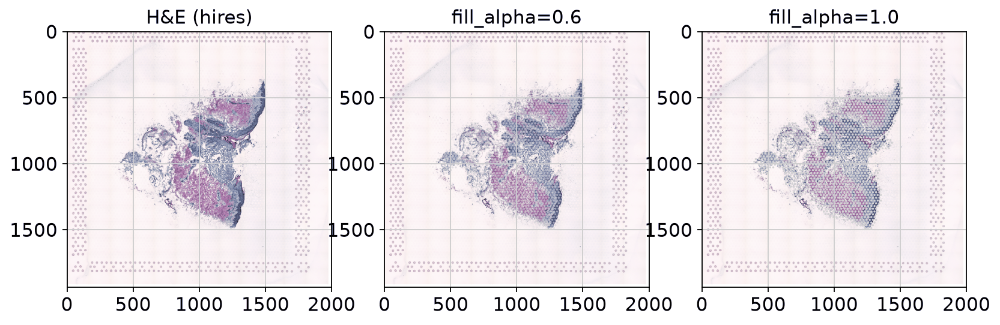

In [24]:
fig, axes = plt.subplots(1, 3, figsize=(12, 6))
sdata_one.pl.render_images("Donor4_Wound7_hires_image").pl.show(
    coordinate_systems="Donor4_Wound7_downscaled_hires", ax=axes[0], title="H&E (hires)")
sdata_one.pl.render_images("Donor4_Wound7_hires_image").pl.render_shapes(
    "Donor4_Wound7", fill_alpha=0.6).pl.show(
    coordinate_systems="Donor4_Wound7_downscaled_hires", ax=axes[1], title="fill_alpha=0.6")
sdata_one.pl.render_images("Donor4_Wound7_hires_image").pl.render_shapes(
    "Donor4_Wound7", fill_alpha=1.0).pl.show(
    coordinate_systems="Donor4_Wound7_downscaled_hires", ax=axes[2], title="fill_alpha=1.0")
plt.show()

### A2 · All 16 sections in one SpatialData object

**Trap.** Spot barcodes are the same in every section (they come from the same slide design). If we concatenate as they are,
`anndata` makes them unique by adding `-1`, `-2`... and we cannot match them with the authors' metadata any more.
Simple fix: prefix the barcodes with the sample name **before** concatenating. With the prefix, the names become
`Donor1_Skin_AAACAAGTATCTCCCA-1`, which is exactly the format of the authors' metadata.

In [25]:
sdatas = {}
for s in SAMPLES:
    sdatas[s] = sdio.visium(f"{DATA}/visium/{s}", dataset_id=s)
    sdatas[s]["table"].obs_names = s + "_" + sdatas[s]["table"].obs_names

sdata = sd.concatenate(list(sdatas.values()), concatenate_tables=True) #concatenate_tables = true tells to sd.concatenate to also merge the anndata tables in a unique table
adata = sdata["table"]
adata

AnnData object with n_obs × n_vars = 25969 × 36600
    obs: 'in_tissue', 'array_row', 'array_col', 'spot_id', 'region'
    uns: 'spatialdata_attrs'
    obsm: 'spatial'

In [30]:
sdata

SpatialData object
├── Images
│     ├── 'Donor1_Skin_hires_image': DataArray[cyx] (3, 2000, 2000)
│     ├── 'Donor1_Skin_lowres_image': DataArray[cyx] (3, 600, 600)
│     ├── 'Donor1_Wound1_hires_image': DataArray[cyx] (3, 2000, 1979)
│     ├── 'Donor1_Wound1_lowres_image': DataArray[cyx] (3, 600, 594)
│     ├── 'Donor1_Wound7_hires_image': DataArray[cyx] (3, 2000, 1979)
│     ├── 'Donor1_Wound7_lowres_image': DataArray[cyx] (3, 600, 594)
│     ├── 'Donor1_Wound30_hires_image': DataArray[cyx] (3, 2000, 1979)
│     ├── 'Donor1_Wound30_lowres_image': DataArray[cyx] (3, 600, 594)
│     ├── 'Donor2_Skin_hires_image': DataArray[cyx] (3, 1937, 2000)
│     ├── 'Donor2_Skin_lowres_image': DataArray[cyx] (3, 581, 600)
│     ├── 'Donor2_Wound1_hires_image': DataArray[cyx] (3, 1937, 2000)
│     ├── 'Donor2_Wound1_lowres_image': DataArray[cyx] (3, 581, 600)
│     ├── 'Donor2_Wound7_hires_image': DataArray[cyx] (3, 1937, 2000)
│     ├── 'Donor2_Wound7_lowres_image': DataArray[cyx] (3, 581, 600)
│  

In [16]:
sdatas

{'Donor1_Skin': SpatialData object
 ├── Images
 │     ├── 'Donor1_Skin_hires_image': DataArray[cyx] (3, 2000, 2000)
 │     └── 'Donor1_Skin_lowres_image': DataArray[cyx] (3, 600, 600)
 ├── Shapes
 │     └── 'Donor1_Skin': GeoDataFrame shape: (1382, 2) (2D shapes)
 └── Tables
       └── 'table': AnnData (1382, 36600)
 with coordinate systems:
     ▸ 'Donor1_Skin', with elements:
         Donor1_Skin_hires_image (Images), Donor1_Skin_lowres_image (Images), Donor1_Skin (Shapes)
     ▸ 'Donor1_Skin_downscaled_hires', with elements:
         Donor1_Skin_hires_image (Images), Donor1_Skin (Shapes)
     ▸ 'Donor1_Skin_downscaled_lowres', with elements:
         Donor1_Skin_lowres_image (Images), Donor1_Skin (Shapes),
 'Donor1_Wound1': SpatialData object
 ├── Images
 │     ├── 'Donor1_Wound1_hires_image': DataArray[cyx] (3, 2000, 1979)
 │     └── 'Donor1_Wound1_lowres_image': DataArray[cyx] (3, 600, 594)
 ├── Shapes
 │     └── 'Donor1_Wound1': GeoDataFrame shape: (2050, 2) (2D shapes)
 └── Tabl

In [ ]:
adata.obs.groupby("sample", observed=True).size()

In [39]:
adata.var_names_make_unique()   # a few gene symbols are duplicated in the 10x reference
adata.obs["sample"] = adata.obs["region"].astype(str)
adata.obs["donor"] = adata.obs["sample"].str.split("_").str[0]
adata.obs["condition"] = pd.Categorical(adata.obs["sample"].str.split("_").str[1], categories=CONDITIONS)

### Sequencing batch

From the paper, we know that **Donor3 and Donor4 were sequenced together**, while Donor1 and Donor2 were each sequenced separately. So there are 4 donors but only **3 sequencing batches**:

| Donor  | Batch  |
|--------|--------|
| Donor1 | batch1 |
| Donor2 | batch2 |
| Donor3 | batch3 |
| Donor4 | batch3 |

Before creating the `seq_batch` column, keep in mind that **donor and batch are not the same thing**: Donor3 and Donor4 share the same technical effect, so in the next steps (integration, batch correction) you should consider the batch, not the donor.

In [40]:
adata.obs["seq_batch"] = adata.obs["donor"].map({"Donor1": "batch1", "Donor2": "batch2", "Donor3": "batch3", "Donor4": "batch3"})

In [41]:
# authors' annotation (only for the spots they kept)
meta = pd.read_csv(f"{DATA}/visium/GSE241124_spatialseq_metadata_acutewound.txt", sep="\t", index_col=0)
adata.obs["authors_annotation"] = meta["AnnoType"].reindex(adata.obs_names)

In [43]:
# only reading and QC cell
adata.obs.groupby("sample", observed=True).size()

sample
Donor1_Skin       1382
Donor1_Wound1     2050
Donor1_Wound30    1354
Donor1_Wound7     1802
Donor2_Skin        914
Donor2_Wound1     1901
Donor2_Wound30    2364
Donor2_Wound7     1953
Donor3_Skin        793
Donor3_Wound1     1507
Donor3_Wound30    2245
Donor3_Wound7     1749
Donor4_Skin        880
Donor4_Wound1     1745
Donor4_Wound30    1996
Donor4_Wound7     1334
dtype: int64

### A3 · Look at the tissues

A grid of the 16 H&E images. They should notice: tissue sizes and shapes differ a lot; the wound is not always obvious;
some sections are fragmented (Donor1_Skin is in two pieces).

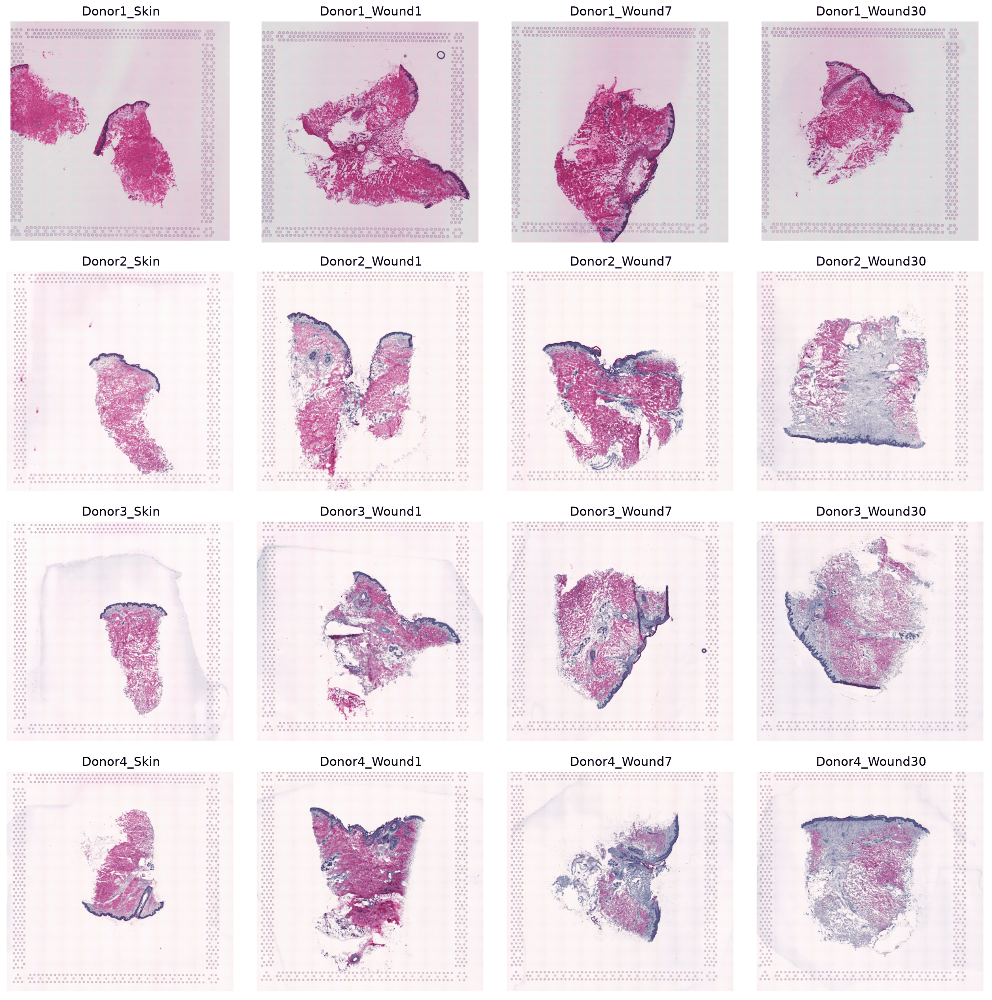

In [47]:
fig, axes = plt.subplots(4, 4, figsize=(16, 16))
for i, s in enumerate(SAMPLES):
    ax = axes[i // 4, i % 4]
    sdata.pl.render_images(f"{s}_lowres_image").pl.show(coordinate_systems=f"{s}_downscaled_lowres", ax=ax, title=s)
    ax.axis("off")
plt.tight_layout()
plt.show()

***
# Part B · Quality control and filtering (Day 1, ≈ 14:00–15:00)

**Goal.** Compute the usual QC metrics per spot, compare sections, **look at them on the tissue**, decide the filters,
and compare with what the authors did.

In [48]:
adata.var["mt"] = adata.var_names.str.startswith("MT-")
adata.var["ribo"] = adata.var_names.str.startswith(("RPS", "RPL"))
adata.var["hb"] = adata.var_names.isin(["HBA1", "HBA2", "HBB", "HBD"])
sc.pp.calculate_qc_metrics(adata, qc_vars=["mt", "ribo", "hb"], percent_top=None, log1p=False, inplace=True)

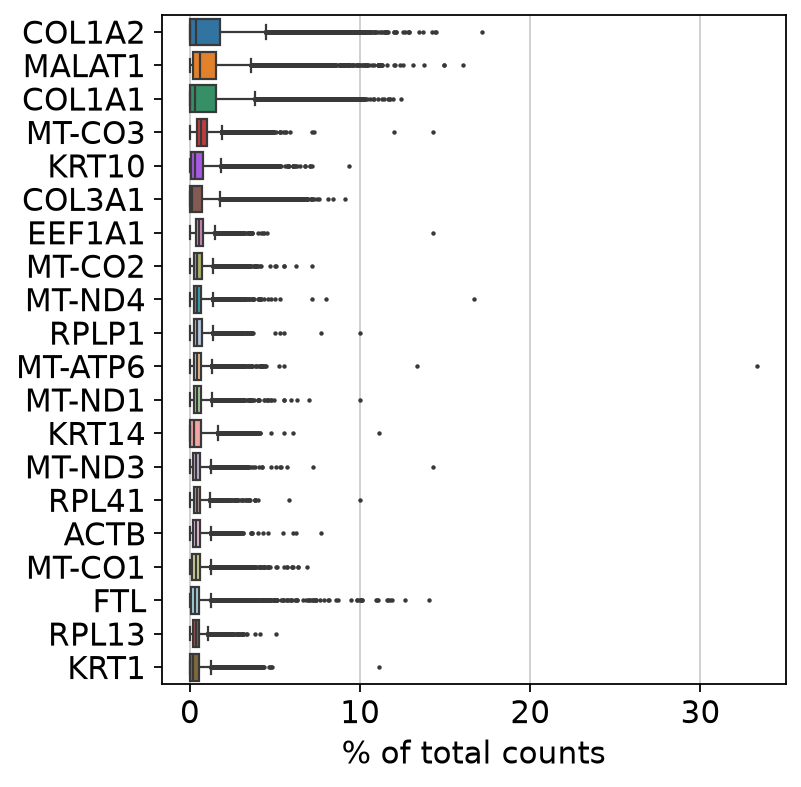

In [49]:
sc.pl.highest_expr_genes(adata, n_top=20)

In [50]:
qc_table = adata.obs.groupby("sample", observed=True)[["total_counts", "n_genes_by_counts", "pct_counts_mt", "pct_counts_hb"]].median().round(1)
qc_table

,total_counts,n_genes_by_counts,pct_counts_mt,pct_counts_hb
sample,,,,
Donor1_Skin,863.5,524.5,6.1,0.0
Donor1_Wound1,413.5,312.0,5.1,0.0
Donor1_Wound30,1342.5,817.5,4.8,0.0
Donor1_Wound7,1698.0,933.5,3.3,0.0
Donor2_Skin,827.0,564.5,3.9,0.0
Donor2_Wound1,895.0,627.0,2.6,0.1
Donor2_Wound30,2272.5,1178.5,3.1,0.0
Donor2_Wound7,394.0,313.0,5.2,0.0
Donor3_Skin,312.0,233.0,3.9,0.0


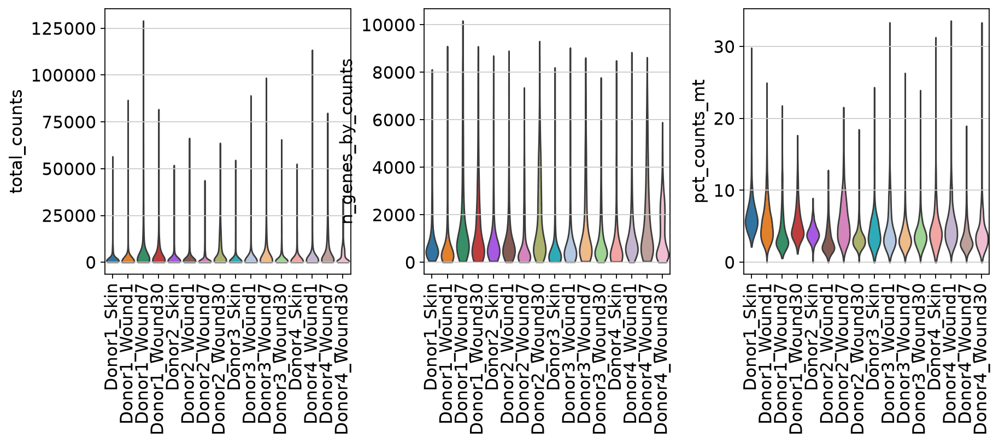

In [51]:
sc.pl.violin(adata, ["total_counts", "n_genes_by_counts", "pct_counts_mt"], groupby="sample",
             rotation=90, stripplot=False, multi_panel=True)

### B1 · QC metrics on the tissue

One donor at a time (4 sections)

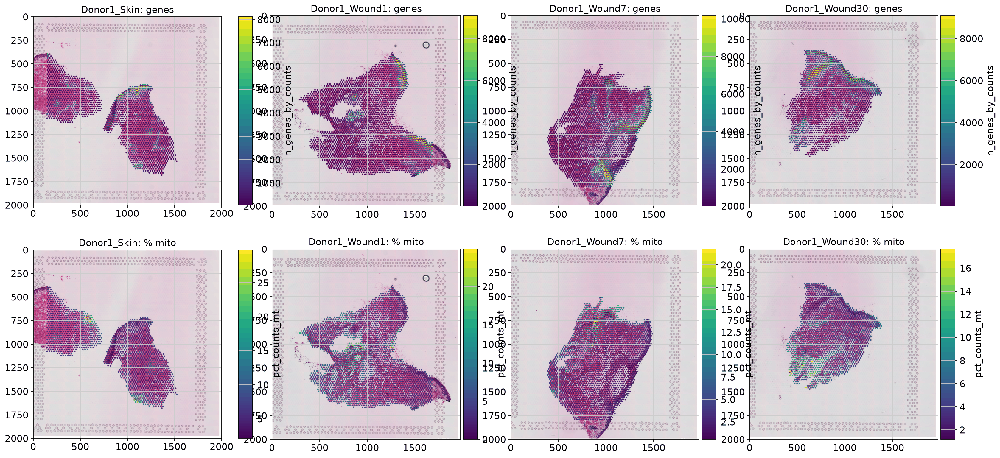

In [53]:
donor = "Donor1"
fig, axes = plt.subplots(2, 4, figsize=(20, 10))
for j, c in enumerate(CONDITIONS):
    s = f"{donor}_{c}"
    sdata.pl.render_images(f"{s}_hires_image").pl.render_shapes(
        s, color="n_genes_by_counts", table_name="table").pl.show(
        coordinate_systems=f"{s}_downscaled_hires", ax=axes[0, j], title=f"{s}: genes")
    sdata.pl.render_images(f"{s}_hires_image").pl.render_shapes(
        s, color="pct_counts_mt", table_name="table").pl.show(
        coordinate_systems=f"{s}_downscaled_hires", ax=axes[1, j], title=f"{s}: % mito")
plt.tight_layout()
plt.show()

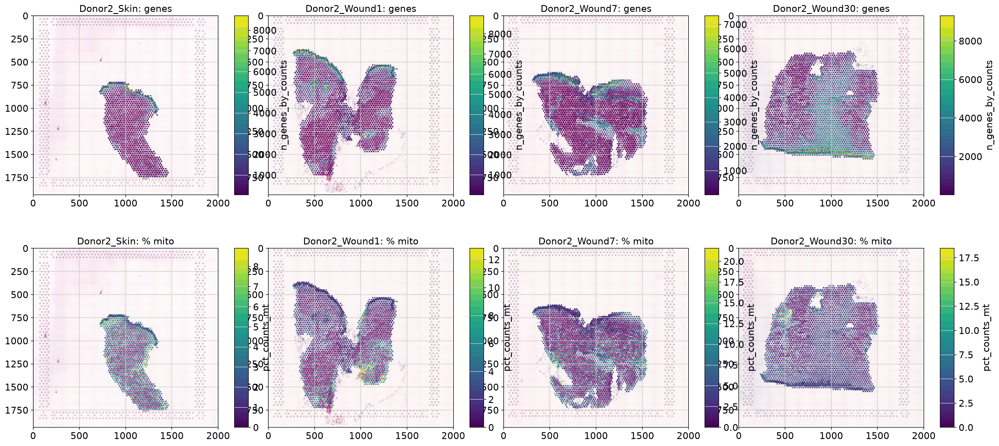

In [52]:
donor = "Donor2"
fig, axes = plt.subplots(2, 4, figsize=(20, 10))
for j, c in enumerate(CONDITIONS):
    s = f"{donor}_{c}"
    sdata.pl.render_images(f"{s}_hires_image").pl.render_shapes(
        s, color="n_genes_by_counts", table_name="table").pl.show(
        coordinate_systems=f"{s}_downscaled_hires", ax=axes[0, j], title=f"{s}: genes")
    sdata.pl.render_images(f"{s}_hires_image").pl.render_shapes(
        s, color="pct_counts_mt", table_name="table").pl.show(
        coordinate_systems=f"{s}_downscaled_hires", ax=axes[1, j], title=f"{s}: % mito")
plt.tight_layout()
plt.show()

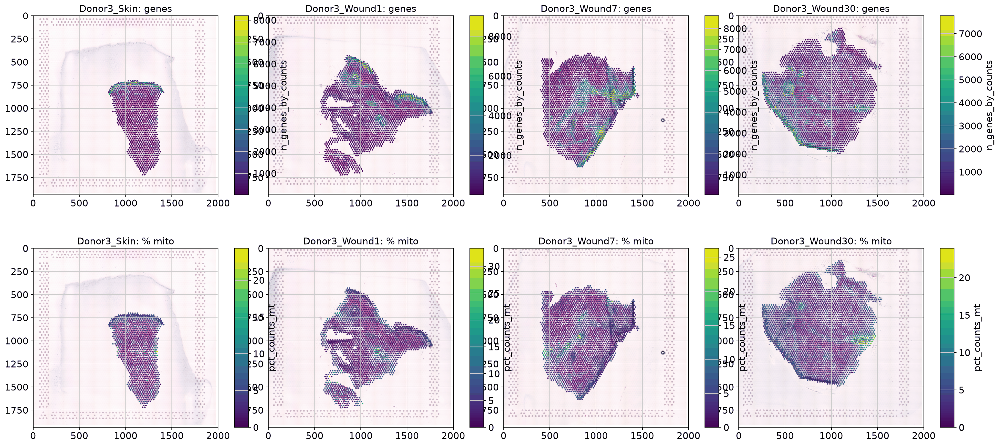

In [54]:
donor = "Donor3"
fig, axes = plt.subplots(2, 4, figsize=(20, 10))
for j, c in enumerate(CONDITIONS):
    s = f"{donor}_{c}"
    sdata.pl.render_images(f"{s}_hires_image").pl.render_shapes(
        s, color="n_genes_by_counts", table_name="table").pl.show(
        coordinate_systems=f"{s}_downscaled_hires", ax=axes[0, j], title=f"{s}: genes")
    sdata.pl.render_images(f"{s}_hires_image").pl.render_shapes(
        s, color="pct_counts_mt", table_name="table").pl.show(
        coordinate_systems=f"{s}_downscaled_hires", ax=axes[1, j], title=f"{s}: % mito")
plt.tight_layout()
plt.show()

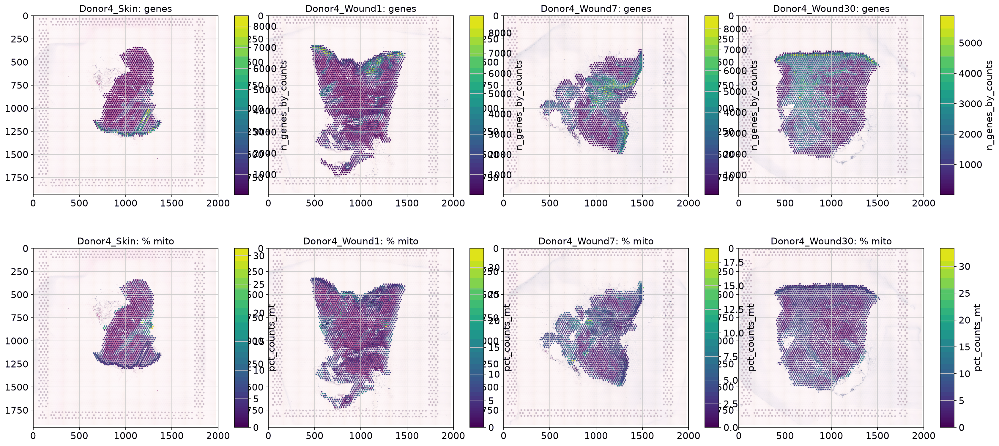

In [55]:
donor = "Donor4"
fig, axes = plt.subplots(2, 4, figsize=(20, 10))
for j, c in enumerate(CONDITIONS):
    s = f"{donor}_{c}"
    sdata.pl.render_images(f"{s}_hires_image").pl.render_shapes(
        s, color="n_genes_by_counts", table_name="table").pl.show(
        coordinate_systems=f"{s}_downscaled_hires", ax=axes[0, j], title=f"{s}: genes")
    sdata.pl.render_images(f"{s}_hires_image").pl.render_shapes(
        s, color="pct_counts_mt", table_name="table").pl.show(
        coordinate_systems=f"{s}_downscaled_hires", ax=axes[1, j], title=f"{s}: % mito")
plt.tight_layout()
plt.show()

### Spatial QC maps: why we look at them

For each donor we plot its 4 sections (`Skin`, `Wound1`, `Wound7`, `Wound30`) side by side, coloured by:

- **`n_genes_by_counts`**: number of genes detected in each spot (top row);
- **`pct_counts_mt`**: percentage of counts coming from mitochondrial genes (bottom row).

**Why it matters**

- **QC has to be read in space, not only in distributions.** A violin plot tells us *how many* spots have low values, but not *where* they are. On the tissue we can see whether they are scattered (technical noise) or grouped in a region (tissue structure).
- **Technical artefact or biology?** Spots with few genes often sit over acellular dermis or at the tissue edge, which is not a failed spot. A high `pct_counts_mt` in a compact region can reflect metabolically active tissue. In dissociated scRNA-seq the same value would flag dying cells, but in intact Visium tissue it does not, which is why the paper does not filter spots on `% mt`.
- **Choosing thresholds.** These maps help us check that a cut-off such as "fewer than 100 genes" removes empty or poor regions and not real tissue.
- **Comparing conditions.** Seeing the 4 sections of a donor together shows how depth and quality change from healthy skin to day 30 of wound healing.


### B2 · Filtering


In [57]:
kept = {}
for t in [100, 150, 200, 300]:
    kept[f">= {t} genes"] = (adata.obs["n_genes_by_counts"] >= t).groupby(adata.obs["sample"], observed=True).mean().round(2)
pd.DataFrame(kept)

,>= 100 genes,>= 150 genes,>= 200 genes,>= 300 genes
sample,,,,
Donor1_Skin,1.00,0.99,0.97,0.80
Donor1_Wound1,0.97,0.84,0.70,0.52
Donor1_Wound7,1.00,1.00,0.99,0.92
Donor1_Wound30,1.00,1.00,0.97,0.82
Donor2_Skin,0.99,0.95,0.91,0.80
Donor2_Wound1,0.99,0.95,0.90,0.81
Donor2_Wound7,0.90,0.76,0.65,0.52
Donor2_Wound30,1.00,0.99,0.97,0.89
Donor3_Skin,0.93,0.76,0.58,0.39


In [58]:
adata_all = adata.copy()   # unfiltered table, kept for the comparison with the authors

In [59]:
print("before:", adata.shape)
sc.pp.filter_cells(adata, min_genes=100)
sc.pp.filter_genes(adata, min_cells=10)
remove = adata.var_names.str.startswith("MT-") | adata.var_names.isin(["MALAT1", "HBA1", "HBA2", "HBB", "HBD"])
adata = adata[:, ~remove].copy()
print("after:", adata.shape)

before: (25969, 36600)
after: (25320, 20855)


In [60]:
sdata.tables["table"] = adata
sdata.write(f"{OUT}/visium_filtered.zarr", overwrite=True)

***
# Part C · Normalisation, exploration, dimensionality reduction, DGE 

In [63]:
sdata = sd.read_zarr(f"{OUT}/visium_filtered.zarr")
adata = sdata["table"]

### C1 · Normalisation


In [64]:
adata.layers["counts"] = adata.X.copy()
sc.pp.normalize_total(adata, target_sum=1e4)
sc.pp.log1p(adata)

### C2 · Highly variable genes, PCA

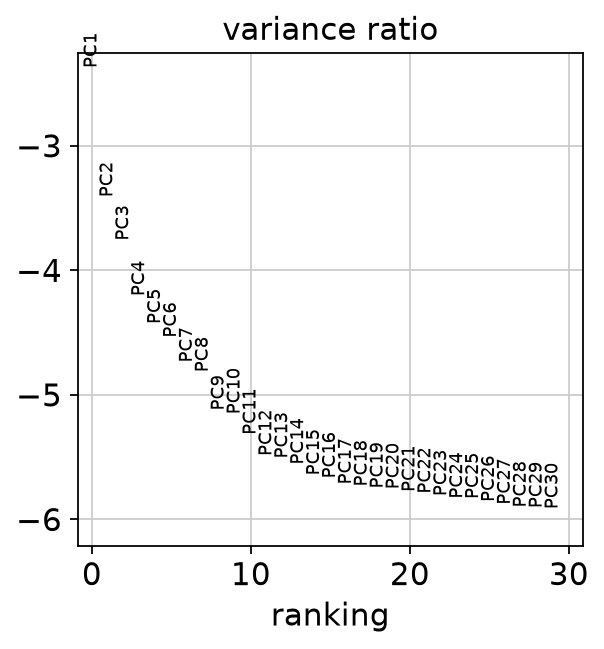

In [65]:
sc.pp.highly_variable_genes(adata, n_top_genes=3000, batch_key="sample")
sc.tl.pca(adata, n_comps=30)
sc.pl.pca_variance_ratio(adata, n_pcs=30, log=True)

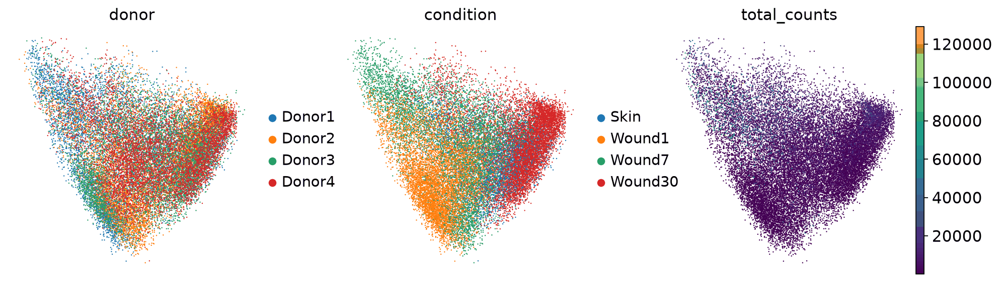

In [66]:
sc.pl.pca(adata, color=["donor", "condition", "total_counts"], ncols=3)

### Interpreting the PCA

The PCA colored by `donor`, `condition` and `total_counts` shows three things:

- **Donors overlap well.** There is no strong donor-driven separation along PC1/PC2, so batch effects do not dominate at this level.
- **Condition drives the main axes.** Spots form a continuous gradient (Wound1 → Wound7 → Wound30, with Wound30 approaching Skin) rather than distinct groups. This is consistent with a **temporal trajectory of wound healing**.
- **Sequencing depth is not the main driver.** Most spots have low `total_counts`, with a few high-count outliers. A depth-related gradient is visible but does not explain the overall structure.


### C3 · Neighbours, UMAP, Leiden

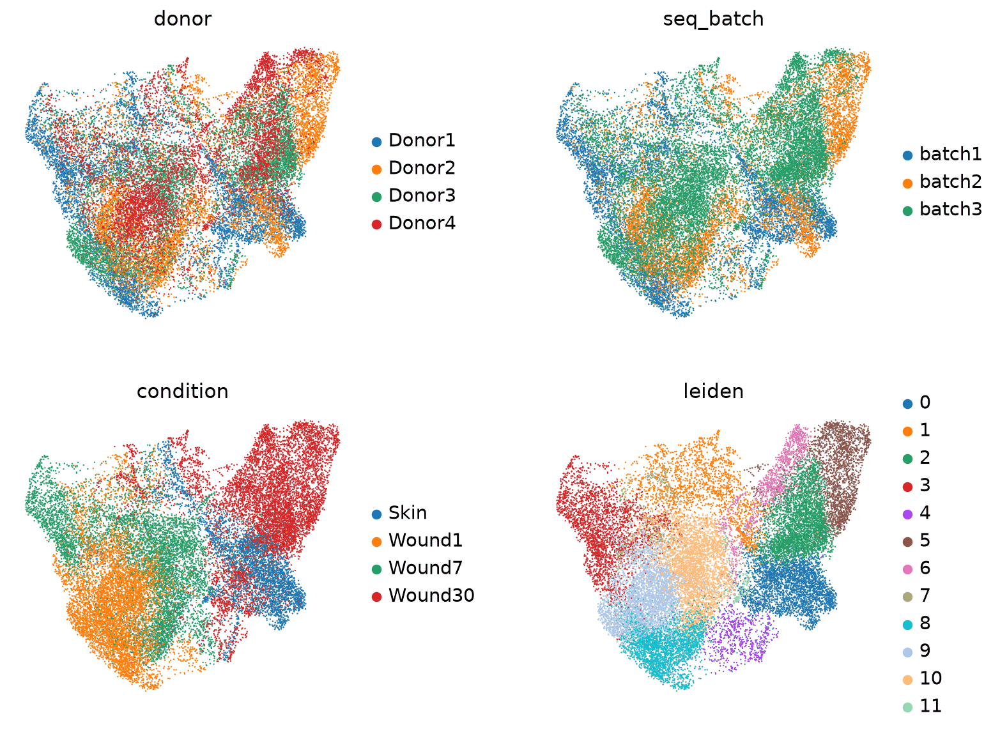

In [67]:
sc.pp.neighbors(adata, n_pcs=20)
sc.tl.umap(adata)
sc.tl.leiden(adata, resolution=0.5, flavor="igraph", n_iterations=2, key_added="leiden")
sc.pl.umap(adata, color=["donor", "seq_batch", "condition", "leiden"], ncols=2, wspace=0.4)

In [74]:
pd.crosstab(adata.obs["leiden"], adata.obs["donor"], normalize='index').round(2)

donor,Donor1,Donor2,Donor3,Donor4
leiden,,,,
0,0.64,0.26,0.04,0.07
1,0.26,0.25,0.22,0.27
2,0.02,0.07,0.61,0.30
3,0.70,0.09,0.09,0.11
4,0.44,0.25,0.19,0.12
5,0.00,0.82,0.01,0.17
6,0.00,0.11,0.22,0.67
7,0.50,0.03,0.29,0.19
8,0.45,0.35,0.14,0.06


In [70]:
pd.crosstab(adata.obs["leiden"], adata.obs["seq_batch"], normalize="index").round(2)

seq_batch,batch1,batch2,batch3
leiden,,,
0,0.64,0.26,0.11
1,0.26,0.25,0.49
2,0.02,0.07,0.91
3,0.70,0.09,0.21
4,0.44,0.25,0.31
5,0.00,0.82,0.18
6,0.00,0.11,0.88
7,0.50,0.03,0.48
8,0.45,0.35,0.20


In [71]:
pd.crosstab(adata.obs["leiden"], adata.obs["condition"], normalize="index").round(2)

condition,Skin,Wound1,Wound7,Wound30
leiden,,,,
0,0.67,0.00,0.01,0.31
1,0.34,0.15,0.16,0.35
2,0.24,0.00,0.01,0.75
3,0.01,0.26,0.72,0.01
4,0.14,0.18,0.39,0.29
5,0.00,0.00,0.00,1.00
6,0.06,0.00,0.17,0.78
7,0.01,0.28,0.20,0.50
8,0.01,0.73,0.25,0.01


Is there a low-quality cluster? Median depth per cluster, and the fraction of its spots that the authors kept:

In [76]:
adata.obs.groupby("leiden", observed=True).agg(
    n_spots=("total_counts", "size"),
    median_counts=("total_counts", "median"),
    median_genes=("n_genes_by_counts", "median"),
).round(2)

,n_spots,median_counts,median_genes
leiden,,,
0,2976,759.0,505.0
1,1807,9790.0,3366.0
2,3439,410.0,309.0
3,2712,1801.0,985.5
4,701,5536.0,2205.0
5,2259,2623.0,1331.0
6,1229,4362.0,1862.0
7,406,11719.5,3715.5
8,2689,257.0,213.0


### C4 · Marker genes and annotation of the clusters

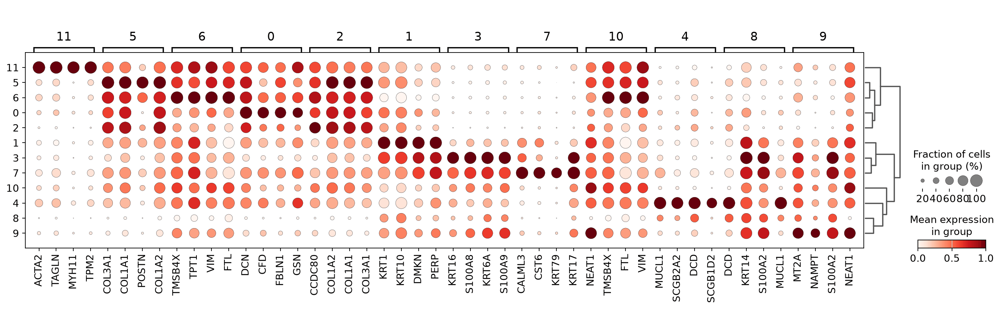

In [77]:
sc.tl.rank_genes_groups(adata, groupby="leiden", method="wilcoxon")
sc.pl.rank_genes_groups_dotplot(adata, n_genes=4, standard_scale="var")

In [78]:
pd.DataFrame(adata.uns["rank_genes_groups"]["names"]).head(8)

,0,1,2,3,4,5,6,7,8,9,10,11
0,DCN,KRT1,CCDC80,KRT16,MUCL1,COL3A1,TMSB4X,CALML3,DCD,MT2A,NEAT1,ACTA2
1,CFD,KRT10,COL1A2,S100A8,SCGB2A2,COL1A1,TPT1,CST6,KRT14,NAMPT,TMSB4X,TAGLN
2,FBLN1,DMKN,COL1A1,KRT6A,DCD,POSTN,VIM,KRT79,S100A2,S100A2,FTL,MYH11
3,GSN,PERP,COL3A1,S100A9,SCGB1D2,COL1A2,FTL,KRT17,MUCL1,NEAT1,VIM,TPM2
4,CCN5,KRT2,IGFBP5,KRT14,KRT19,SPARC,SELENOP,LGALS7B,KRT6A,PTMA,CD74,MYL9
5,S100A6,KRTDAP,DCN,KRT6B,PIP,COL6A1,LUM,DHCR24,SCGB2A2,S100A9,TMSB10,ACTG2
6,CST3,DSG1,SPARC,SPRR1B,SCGB1B2P,LUM,YBX1,TRIM29,KRT10,KRT6A,CTSB,MYLK
7,APOD,DSP,RP11-596C23.6,KRT17,ATP1A1,FN1,FTH1,FDPS,ACTB,HSP90AA1,HLA-DRA,CSRP1


With the markers reported in the paper for the ST clusters:

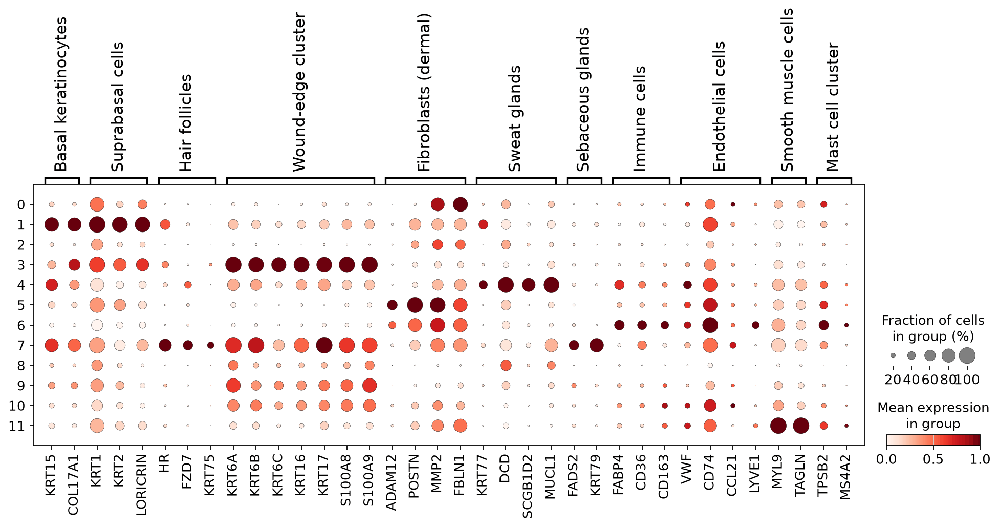

In [79]:
markers = pd.read_csv(f"{DATA}/paper_marker_genes.csv")
st_markers = {}
for _, row in markers[(markers["dataset"] == "ST-seq") & (markers["granularity"] == "major")].iterrows():
    st_markers[row["cell_type"]] = [g for g in row["marker_genes"].split(";") if g in adata.var_names]
sc.pl.dotplot(adata, st_markers, groupby="leiden", standard_scale="var")

### C5 · Back to space


WARNING  render_shapes: Not enough colors provided for category '11', using na_color.                              
WARNING  render_shapes: Not enough colors provided for category '11', using na_color.                              
WARNING  render_shapes: Not enough colors provided for category '11', using na_color.                              
WARNING  render_shapes: Not enough colors provided for category '10', using na_color.                              
WARNING  render_shapes: Not enough colors provided for category '11', using na_color.                              


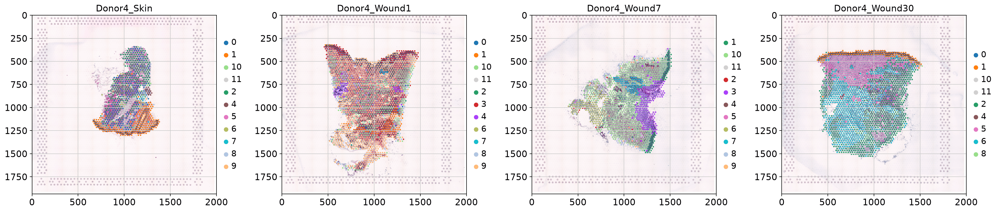

In [80]:
donor = "Donor4"
fig, axes = plt.subplots(1, 4, figsize=(22, 5.5))
for j, c in enumerate(CONDITIONS):
    s = f"{donor}_{c}"
    sdata.pl.render_images(f"{s}_hires_image").pl.render_shapes(
        s, color="leiden", table_name="table").pl.show(
        coordinate_systems=f"{s}_downscaled_hires", ax=axes[j], title=s)
plt.tight_layout()
plt.show()

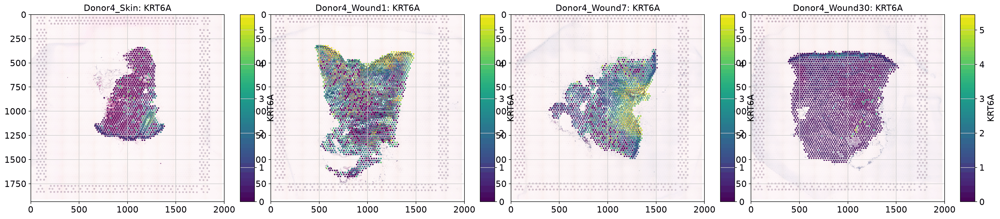

In [81]:
gene = "KRT6A"   # try also KRT16, S100A8, MMP9, COL1A1, POSTN, CXCL8
vmax = np.percentile(adata[:, gene].X.toarray(), 99)
fig, axes = plt.subplots(1, 4, figsize=(22, 5.5))
for j, c in enumerate(CONDITIONS):
    s = f"{donor}_{c}"
    sdata.pl.render_images(f"{s}_hires_image").pl.render_shapes(
        s, color=gene, table_name="table", norm=Normalize(vmin=0, vmax=vmax)).pl.show(
        coordinate_systems=f"{s}_downscaled_hires", ax=axes[j], title=f"{s}: {gene}")
plt.tight_layout()
plt.show()

In [82]:
sdata.tables["table"] = adata
sdata.write(f"{OUT}/visium_clustered.zarr", overwrite=True)

### C6 · Spatially variable genes (if time)

Spatial graph on the Visium hexagonal grid (6 neighbours), **one section at a time** for Moran's I
(spots of different sections are not neighbours). Squidpy builds per-section graphs on the whole object with `library_key`.

In [83]:
s = "Donor4_Wound7"
a = adata[adata.obs["sample"] == s].copy()
sq.gr.spatial_neighbors(a, coord_type="grid", n_neighs=6)
sc.pp.highly_variable_genes(a, n_top_genes=2000)
sq.gr.spatial_autocorr(a, mode="moran", genes=a.var_names[a.var["highly_variable"]], n_perms=100, n_jobs=2)
a.uns["moranI"].head(15)

INFO     Creating graph using `None` transform and `1` libraries.                                                  


  0%|          | 0/100 [00:00<?, ?/s]/opt/conda/envs/cnrs-st/lib/python3.11/site-packages/docrep/decorators.py:43: SyntaxWarning: 'n_jobs' is not a valid key!
  doc = func(self, args[0].__doc__, *args[1:], **kwargs)
/opt/conda/envs/cnrs-st/lib/python3.11/site-packages/docrep/decorators.py:43: SyntaxWarning: 'n_jobs' is not a valid key!
  doc = func(self, args[0].__doc__, *args[1:], **kwargs)
/opt/conda/envs/cnrs-st/lib/python3.11/site-packages/docrep/decorators.py:43: SyntaxWarning: 'show_progress_bar' is not a valid key!
  doc = func(self, args[0].__doc__, *args[1:], **kwargs)
/opt/conda/envs/cnrs-st/lib/python3.11/site-packages/docrep/decorators.py:43: SyntaxWarning: 'show_progress_bar' is not a valid key!
  doc = func(self, args[0].__doc__, *args[1:], **kwargs)
100%|██████████| 100/100 [00:14<00:00,  6.86/s]


,I,pval_norm,var_norm,pval_z_sim,pval_sim,var_sim,pval_norm_fdr_bh,pval_z_sim_fdr_bh,pval_sim_fdr_bh
FABP4,0.560997,0.0,0.000272,0.0,0.009901,0.000349,0.0,0.0,0.034438
S100A8,0.553287,0.0,0.000272,0.0,0.009901,0.000528,0.0,0.0,0.034438
KRT6A,0.546026,0.0,0.000272,0.0,0.009901,0.000433,0.0,0.0,0.034438
SPRR1B,0.542192,0.0,0.000272,0.0,0.009901,0.000435,0.0,0.0,0.034438
SBSN,0.534704,0.0,0.000272,0.0,0.009901,0.000452,0.0,0.0,0.034438
S100A7,0.529186,0.0,0.000272,0.0,0.009901,0.000524,0.0,0.0,0.034438
KRT1,0.529008,0.0,0.000272,0.0,0.009901,0.000455,0.0,0.0,0.034438
KRT16,0.517623,0.0,0.000272,0.0,0.009901,0.000436,0.0,0.0,0.034438
PI3,0.516496,0.0,0.000272,0.0,0.009901,0.000388,0.0,0.0,0.034438
KRT6B,0.512248,0.0,0.000272,0.0,0.009901,0.000517,0.0,0.0,0.034438


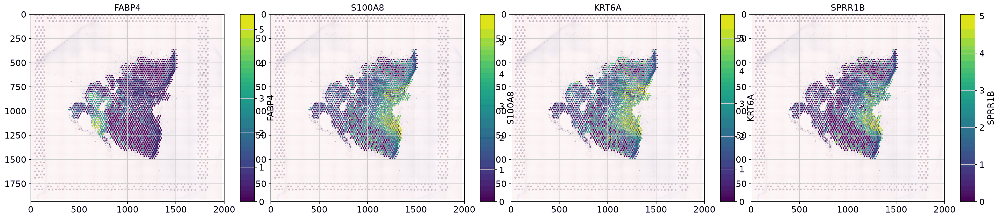

In [84]:
top_svg = a.uns["moranI"].index[:4].tolist()
fig, axes = plt.subplots(1, 4, figsize=(22, 5.5))
for j, g in enumerate(top_svg):
    sdata.pl.render_images(f"{s}_hires_image").pl.render_shapes(
        s, color=g, table_name="table").pl.show(coordinate_systems=f"{s}_downscaled_hires", ax=axes[j], title=g)
plt.tight_layout()
plt.show()

### Spatially variable genes: what we did, the statistics behind it, and how to read the output

#### 1. The question

A **spatially variable gene (SVG)** is a gene whose expression is not randomly scattered over the tissue but forms a spatial pattern: neighbouring spots have similar values. This is different from a **highly variable gene (HVG)**. An HVG varies a lot between spots, but the HVG test ignores where the spots are. If you shuffled the spot positions, the HVG list would not change, but the SVG list would.

SVGs are useful to:
- find the genes that describe tissue structure;
- choose genes for spatial clustering and domains;
- find structures that are not obvious on the H&E.

#### 2. The procedure, step by step

```python
s = "Donor4_Wound7"
a = adata[adata.obs["sample"] == s].copy()                       # (1) one section
sq.gr.spatial_neighbors(a, coord_type="grid", n_neighs=6)        # (2) spatial graph
sc.pp.highly_variable_genes(a, n_top_genes=2000)                 # (3) candidate genes
sq.gr.spatial_autocorr(a, mode="moran", genes=..., n_perms=100)  # (4) Moran's I + permutation test
a.uns["moranI"].head(15)                                         # (5) ranking
```

1. **One section at a time.** Spots of different sections are not neighbours in space, so a spatial statistic only makes sense within a section. On the whole object, `sq.gr.spatial_neighbors(..., library_key="sample")` builds one graph per section.
2. **Spatial graph.** Visium spots sit on a hexagonal grid: 55 µm spots, 100 µm centre-to-centre. With `coord_type="grid", n_neighs=6`, each spot is connected to its 6 immediate neighbours (one ring). This gives the **spatial weights matrix** $W$, with $w_{ij} = 1$ if spots $i$ and $j$ are neighbours and $0$ otherwise. It is stored in `a.obsp["spatial_connectivities"]`. The log line `Creating graph using None transform and 1 libraries` means that the graph is not transformed at this step and that there is one section.
3. **Candidate genes.** We test the 2,000 HVGs of the section, not all ~20,000 genes. This is faster, and genes with almost no variance cannot be spatially variable. The limitation is that a gene with a clear but low-amplitude pattern can be missed.
4. **Moran's I for each gene.** It is computed on the log-normalised expression (`X`), with a permutation test (100 permutations).
5. **Ranking.** The table is sorted by decreasing Moran's I.

#### 3. The statistics: Moran's I

For one gene, let $x_i$ be its log-normalised expression in spot $i$, $\bar{x}$ the mean over the $N$ spots of the section, and $z_i = x_i - \bar{x}$.

$$
I = \frac{N}{S_0}\,\frac{\sum_{i}\sum_{j} w_{ij}\, z_i z_j}{\sum_i z_i^2},
\qquad S_0 = \sum_i \sum_j w_{ij}
$$

- The **numerator** sums $z_i z_j$ over pairs of neighbours. It is positive when neighbours are on the same side of the mean, either both high or both low.
- The **denominator** is the variance of the gene, so $I$ does not depend on the expression scale.
- Squidpy **row-standardises** the weights by default (`transformation=True`): each row of $W$ sums to 1, so $S_0 = N$. Then $I = \sum_i z_i \,(\sum_j w_{ij} z_j) / \sum_i z_i^2$, where the term in brackets is the mean of the neighbours of spot $i$ (the **spatial lag**). In other words, $I$ is the slope of the regression of "average of my neighbours" on "my value" (the Moran scatterplot).

**How to read the value**

| Moran's I | Meaning |
|---|---|
| close to $E[I] = -1/(N-1) \approx 0$ | no spatial structure (values randomly placed) |
| > 0 (up to ≈ 1) | positive autocorrelation: similar values cluster together (a layer, a patch, a gradient) |
| < 0 | negative autocorrelation: neighbours tend to be different (checkerboard; rare in tissues) |

In Visium tissue, $I \approx 0.5$ is a very strong pattern. $I \approx 0.1$ is weak, but it can still be "significant" with thousands of spots.

**Significance**

- **Analytical test** (`pval_norm`). Under the null hypothesis of no spatial autocorrelation, $I$ is approximately normal with mean $E[I] = -1/(N-1)$. Its variance depends only on $W$ (Cliff & Ord 1981):
  $\mathrm{Var}(I) = \dfrac{N^2 S_1 - N S_2 + 3 S_0^2}{S_0^2 (N^2-1)} - E[I]^2$, with $S_1 = \tfrac12\sum_{ij}(w_{ij}+w_{ji})^2$ and $S_2 = \sum_i (\sum_j w_{ij} + \sum_j w_{ji})^2$. Then $z = (I - E[I]) / \sqrt{\mathrm{Var}(I)}$.
- **Permutation test** (`pval_sim`, computed because `n_perms=100`). The expression values are shuffled over the spots while the positions and the graph stay fixed, and $I$ is recomputed 100 times. The p-value is the fraction of permuted $I$ at least as large as the observed one: $p = (\#\{I_{perm} \ge I_{obs}\} + 1)/(n_{perms}+1)$.
  - The test makes no normality assumption.
  - The null hypothesis is exchangeability: any arrangement of these values over these spots is equally likely.
  - By default the test is one-sided and looks for positive autocorrelation (`two_tailed=False`).
- With 100 permutations, the smallest possible p-value is $1/101 \approx 0.0099$, so all strong SVGs hit this floor. Finer p-values need more permutations, which is slower.
- Squidpy corrects for multiple testing across genes with Benjamini–Hochberg (`corr_method="fdr_bh"`, columns `..._fdr_bh`).

**Columns of `a.uns["moranI"]`**
- `I`: the statistic.
- `pval_norm` and `var_norm`: the analytical test.
- `pval_sim`, `pval_z_sim` and `var_sim`: the permutation test.
- The FDR-corrected versions of the p-values.

**In practice, rank by `I`, not by p-value.** With ~2,000 spots, almost every gene with any structure is "significant". The p-value says that there is some pattern; the value of `I` says how strong it is. Benchmarks also show that the p-values of most SVG methods are poorly calibrated (Li et al. 2025).

#### 4. How to read our output (Donor4_Wound7)

**The warnings.** `SyntaxWarning: 'n_jobs' is not a valid key!` and `'show_progress_bar' ...` come from `docrep`, the library squidpy uses to build its docstrings. They are harmless and do not affect the results. They appear despite `warnings.filterwarnings("ignore")`, most probably because `n_jobs=2` starts worker processes that re-import squidpy and do not inherit the filter. With `n_jobs=1` they should disappear, at the cost of a slightly slower run.

**The top genes and what they show on the tissue:**
- **FABP4** (fatty-acid binding protein 4, made by adipocytes) forms a compact patch at the lower left of the section. This is **subcutaneous adipose tissue** at the base of the biopsy.
- **S100A8** (an alarmin made by activated keratinocytes and neutrophils), **KRT6A** (a keratin of activated, hyperproliferative keratinocytes) and **SPRR1B** (cornified envelope, stressed epidermis) all lie along the right border of the section. This is the **activated epidermis at the wound edge**.

So the 4 top SVGs describe only **2 structures**: fat and wound-edge epidermis. This is typical of Moran's I, which rewards **large, contiguous, high-contrast structures**. Small structures such as vessels, sweat glands and hair follicles cover few spots and get a lower $I$, even when their pattern is very clear. Many top genes are also redundant: they share the same pattern because they mark the same structure.

#### 5. Limits to keep in mind

- **Scale.** With $W$ = immediate neighbours, $I$ measures structure at a scale of ~100 µm. A wider neighbourhood (`n_rings=2` or more) favours broader gradients.
- **Composition, not regulation.** A high $I$ usually means that the gene marks a tissue compartment. It does not mean that the gene is regulated by position within a cell type.
- **Depth is spatial too.** In Visium, the total counts per spot are themselves spatially structured (cell-dense epidermis versus acellular dermis), and log-normalisation does not remove this completely. Genes that follow depth can therefore get a high $I$. A useful baseline is the Moran's I of `total_counts` itself.
- **Edges and shape.** Spots at the tissue border have fewer neighbours, and very fragmented sections behave differently from compact ones. Do not compare $I$ values between sections of very different size and shape.
- **HVG pre-selection** decides which genes can be found at all.
- **Alternatives.**
  - Geary's C (`mode="geary"`) is based on differences between neighbours and is more sensitive to local structure.
  - Dedicated SVG methods model the expression as a function of the coordinates. SpatialDE uses Gaussian processes. SPARK and SPARK-X use spatial kernels, and SPARK-X is very fast. nnSVG uses nearest-neighbour Gaussian processes and scales to large datasets.
  - Different methods often return quite different SVG lists (Charitakis et al. 2023; Chen et al. 2024). In the most extensive benchmark, SPARK-X performs best and Moran's I is a competitive, simple baseline (Li et al. 2025).

#### 6. Where the method comes from

This analysis is **not** in the wound-healing paper (Liu et al., Cell Stem Cell 2025). It is the standard approach of the scverse ecosystem, built on classic spatial statistics: squidpy's Visium tutorials use `spatial_neighbors` and `spatial_autocorr(mode="moran")` with a permutation test.

- Moran PAP (1950). Notes on continuous stochastic phenomena. *Biometrika* 37:17–23. — The statistic.
- Geary RC (1954). The contiguity ratio and statistical mapping. *The Incorporated Statistician* 5:115–145. — Geary's C.
- Cliff AD, Ord JK (1981). *Spatial Processes: Models and Applications*. Pion, London. — Inference for Moran's I, under normality and randomisation.
- Anselin L (1995). Local indicators of spatial association — LISA. *Geographical Analysis* 27:93–115. — Local Moran's I, which shows the spots that drive the pattern.
- Palla G, Spitzer H, Klein M, et al. (2022). Squidpy: a scalable framework for spatial omics analysis. *Nature Methods* 19:171–178. — The implementation used here.
- Svensson V, Teichmann SA, Stegle O (2018). SpatialDE: identification of spatially variable genes. *Nature Methods* 15:343–346.
- Sun S, Zhu J, Zhou X (2020). Statistical analysis of spatial expression patterns for spatially resolved transcriptomic studies (SPARK). *Nature Methods* 17:193–200.
- Zhu J, Sun S, Zhou X (2021). SPARK-X: non-parametric modeling enables scalable and robust detection of spatial expression patterns for large spatial transcriptomic studies. *Genome Biology* 22:184.
- Weber LM, Saha A, Datta A, Hansen KD, Hicks SC (2023). nnSVG for the scalable identification of spatially variable genes using nearest-neighbor Gaussian processes. *Nature Communications* 14:4059.
- Charitakis N, et al. (2023). Disparities in spatially variable gene calling highlight the need for benchmarking spatial transcriptomics methods. *Genome Biology* 24:209.
- Chen C, Kim HJ, Yang P (2024). Evaluating spatially variable gene detection methods for spatial transcriptomics data. *Genome Biology* 25:18.
- Li Z, Patel ZM, Song D, et al., Pinello L (2025). Systematic benchmarking of computational methods to identify spatially variable genes. *Genome Biology* (doi:10.1186/s13059-025-03731-2).

### C7 · Differential expression between conditions (if time, otherwise Day 2)

The statistical unit is the **donor**, not the spot. Spot-level Wilcoxon tests between conditions (thousands of spots vs thousands of spots)
give absurd p-values because spots of one section are not independent replicates. We aggregate counts per section (pseudobulk)
and use DESeq2 with a paired design (`~ donor + condition`): 4 donors × 2 conditions.

In [85]:
from pydeseq2.dds import DeseqDataSet
from pydeseq2.ds import DeseqStats

sub = adata[adata.obs["condition"].isin(["Skin", "Wound7"])].copy()
pb = sc.get.aggregate(sub, by=["sample", "donor", "condition"], func="sum", layer="counts")
pb.X = pb.layers["sum"]
pb.obs["condition"] = pb.obs["condition"].astype(str)
pb = pb[:, (pb.X >= 10).sum(axis=0) >= 3].copy()   # genes with at least 10 counts in at least 3 sections
pb

AnnData object with n_obs × n_vars = 8 × 14850
    obs: 'sample', 'donor', 'condition'
    var: 'mt', 'ribo', 'hb', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts', 'n_cells', 'highly_variable', 'means', 'dispersions', 'dispersions_norm', 'highly_variable_nbatches', 'highly_variable_intersection'
    layers: 'sum'

In [86]:
dds = DeseqDataSet(adata=pb, design="~donor + condition", quiet=True)
dds.deseq2()
stat = DeseqStats(dds, contrast=["condition", "Wound7", "Skin"], quiet=True)
stat.summary()
res = stat.results_df.sort_values("padj")
print((res["padj"] < 0.05).sum(), "genes at padj < 0.05")
res.head(20)

1828 genes at padj < 0.05


,baseMean,log2FoldChange,lfcSE,stat,pvalue,padj
KRT16,9187.822097,6.400243,0.379422,16.868418,7.682624e-64,1.140870e-59
MMP9,500.402458,5.609695,0.346261,16.200762,4.980586e-59,3.698085e-55
GJB2,3089.499961,4.569822,0.320080,14.277118,3.039113e-46,1.504361e-42
LCE3D,1005.659637,4.011026,0.281744,14.236436,5.443323e-46,2.020834e-42
TNC,993.546314,3.601403,0.258144,13.951158,3.095375e-44,9.193265e-41
DSC2,990.569820,3.792306,0.275535,13.763412,4.230794e-43,1.047121e-39
SERPINB4,500.810129,7.046331,0.536434,13.135499,2.061285e-39,4.372869e-36
LCE3E,371.234635,4.454955,0.351814,12.662798,9.505036e-37,1.764372e-33
CILP,221.679210,-4.579001,0.369791,-12.382684,3.243143e-35,5.351186e-32
S100A2,13189.881543,3.331347,0.285645,11.662545,1.980329e-31,2.940789e-28


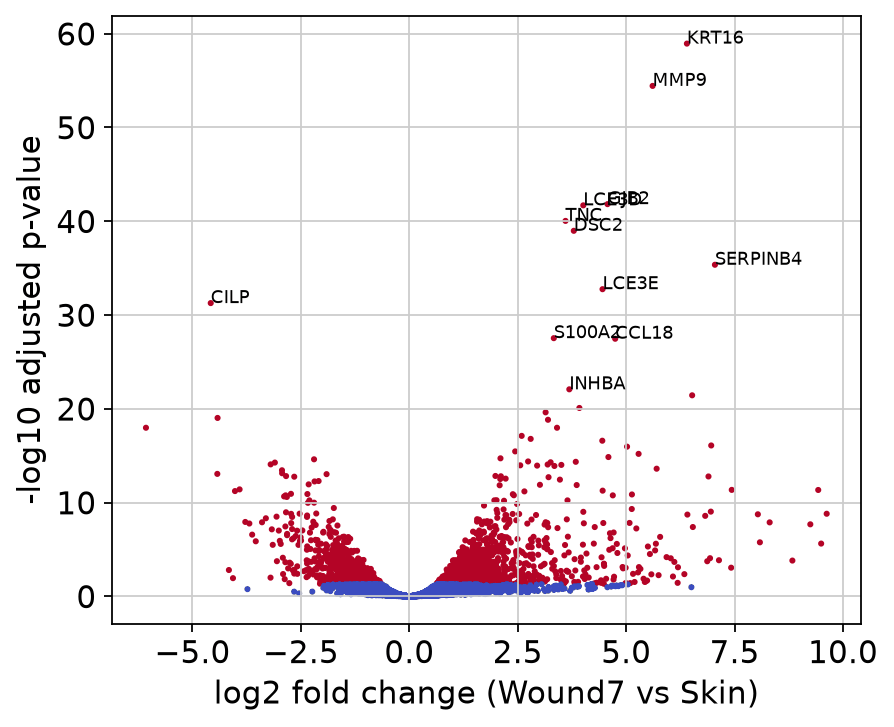

In [87]:
plt.figure(figsize=(6, 5))
plt.scatter(res["log2FoldChange"], -np.log10(res["padj"]), s=3, c=(res["padj"] < 0.05), cmap="coolwarm")
for g in res.index[:12]:
    plt.text(res.loc[g, "log2FoldChange"], -np.log10(res.loc[g, "padj"]), g, fontsize=8)
plt.xlabel("log2 fold change (Wound7 vs Skin)")
plt.ylabel("-log10 adjusted p-value")
plt.show()

***
# Part D · Group project

### D0 · Choose a question and a dataset (10 min, at the end of the morning lecture)

With 4 participants: **two groups**. Each group picks one option.

| Option | Sections | Question | Why it is interesting |
|---|---|---|---|
| **A · Time course in one person** | Donor4 (PWH27), 4 sections | How do the spatial domains of the wound change from Skin to Wound30? Which cell types are where? | Same individual in the scRNA-seq reference: sc–st integration is "fair" |
| **B · Reproducibility across people** | Wound7 of the 4 donors (or Wound1) | Are the wound domains the same in all donors? What is batch, what is biology? | 3 sequencing batches, very different depths: integration is really needed |

In every option, the expected steps are: integration across sections (Harmony) → spatial domains (CellCharter) →
domain markers and composition → sc–st integration (scores and Tangram) → one biological message, with its limits.

### Option A

In [93]:
sdata = sd.read_zarr(f"{OUT}/visium_clustered.zarr")

GROUP_SAMPLES = ["Donor4_Skin", "Donor4_Wound1", "Donor4_Wound7", "Donor4_Wound30"]        # option A
# GROUP_SAMPLES = ["Donor1_Wound7", "Donor2_Wound7", "Donor3_Wound7", "Donor4_Wound7"]     # option B

elements = GROUP_SAMPLES + [f"{s}_hires_image" for s in GROUP_SAMPLES] + [f"{s}_lowres_image" for s in GROUP_SAMPLES]
sdata_g = sdata.subset(elements, filter_tables=True)
adata_g = sdata_g["table"]
adata_g.obs["sample"] = adata_g.obs["sample"].astype("category").cat.remove_unused_categories()
adata_g

AnnData object with n_obs × n_vars = 5769 × 20855
    obs: 'in_tissue', 'array_row', 'array_col', 'spot_id', 'region', 'sample', 'donor', 'condition', 'seq_batch', 'authors_annotation', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'pct_counts_ribo', 'total_counts_hb', 'pct_counts_hb', 'n_genes', 'leiden'
    var: 'mt', 'ribo', 'hb', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts', 'n_cells', 'highly_variable', 'means', 'dispersions', 'dispersions_norm', 'highly_variable_nbatches', 'highly_variable_intersection'
    uns: 'condition_colors', 'donor_colors', 'leiden_colors', 'seq_batch_colors', 'dendrogram_leiden', 'rank_genes_groups', 'leiden', 'sample_colors', 'neighbors', 'hvg', 'umap', 'log1p', 'spatialdata_attrs', 'pca'
    obsm: 'X_umap', 'spatial', 'X_pca'
    varm: 'PCs'
    layers: 'counts'
    obsp: 'distances', 'connectivities'

### Selecting the sections for the group project

**This cell is provided: you do not need to write it, only to choose your option.** It is SpatialData-specific plumbing that you will rarely meet again outside this object.

**What it does**

1. **Reloads the checkpoint** saved at the end of Part C (`visium_clustered.zarr`). It contains all 16 sections, with the normalisation, PCA, UMAP and Leiden clusters computed so far. The images stay on disk and are only read when we plot them.
2. **Selects the sections of your group** in `GROUP_SAMPLES`. Uncomment the line of your option and keep the others commented:
   - **A** · time course in one donor (Donor4: Skin, Wound1, Wound7, Wound30);
   - **B** · the same time point (Wound7) in the four donors;
3. **Keeps only these sections in the `SpatialData` object.** A section is not a single element: it is made of the spots (`shapes`, named like the section) and two images (`<section>_hires_image` and `<section>_lowres_image`). We list all of them in `elements`, then `sdata.subset(...)` returns a new object with only those.
4. **Filters the table too** (`filter_tables=True`). The table is linked to the spots through the `region` column, so only the rows of the spots that are still in the object are kept. Without this option the table would still contain the 16 sections, while the spots and images would only be those of your group.
5. **Extracts the `AnnData`** (`adata_g`): from here on this is the object we work on, as in Part C.
6. **Cleans the `sample` column.** After filtering rows, a pandas categorical column still remembers all its original categories. `remove_unused_categories()` removes the empty ones, so legends, `crosstab` tables and colours only show the sections of your group.

**What to check in the output**

- `adata_g` has fewer spots than the full object, and the same genes. Check the number of spots per section with `adata_g.obs["sample"].value_counts()`: it should list only your sections.
- The columns computed in Part C (`leiden`, `X_pca`, `X_umap`...) are still there, but they were computed on **all 16 sections**. In the next cells we recompute HVGs, PCA and neighbours on the subset, because variance and neighbours depend on which spots are present.

In [92]:
elements

['Donor4_Skin',
 'Donor4_Wound1',
 'Donor4_Wound7',
 'Donor4_Wound30',
 'Donor4_Skin_hires_image',
 'Donor4_Wound1_hires_image',
 'Donor4_Wound7_hires_image',
 'Donor4_Wound30_hires_image',
 'Donor4_Skin_lowres_image',
 'Donor4_Wound1_lowres_image',
 'Donor4_Wound7_lowres_image',
 'Donor4_Wound30_lowres_image']

Recompute HVG and PCA on the subset (the normalised values in `X` stay valid: normalisation is per spot).

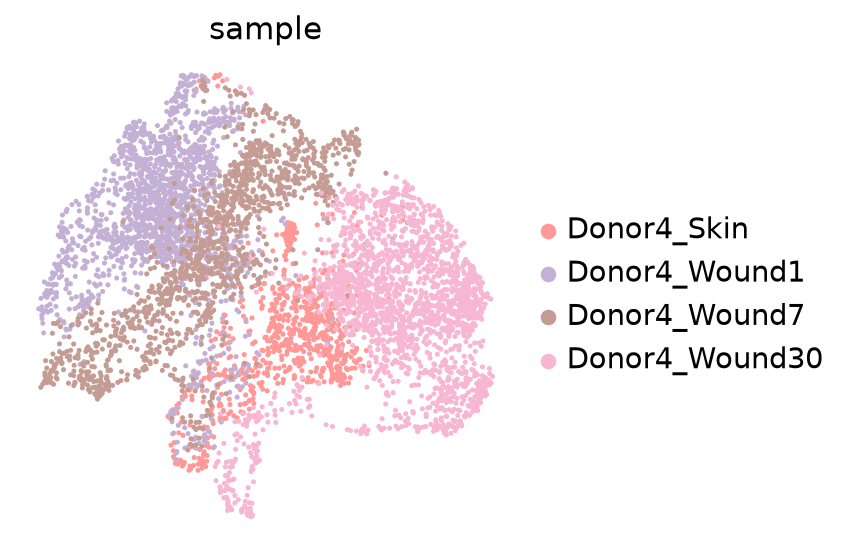

In [94]:
sc.pp.highly_variable_genes(adata_g, n_top_genes=3000, batch_key="sample")
sc.tl.pca(adata_g, n_comps=30)
sc.pp.neighbors(adata_g, n_pcs=30)
sc.tl.umap(adata_g)
sc.pl.umap(adata_g, color=["sample"], wspace=0.5)

### D1 · Integration across sections (Harmony)

Batch variable: the section (`sample`). Harmony corrects the PCA embedding; everything downstream uses `X_pca_harmony`.

The trap to discuss: in option A, the section **is** the time point. Correcting by section can erase real differences between
conditions (over-correction). In option B, the section is the donor (and the sequencing batch): correction is what we want.
How do they check? Shared structures (epidermis, dermis, glands) should mix across sections; structures that exist only in wounds
should stay separate. Compare cluster composition before and after.

2026-11-18 08:39:42,359 - harmonypy - INFO - Computing initial centroids with sklearn.KMeans...
2026-11-18 08:39:44,187 - harmonypy - INFO - sklearn.KMeans initialization complete.
2026-11-18 08:39:44,241 - harmonypy - INFO - Iteration 1 of 10
2026-11-18 08:39:45,012 - harmonypy - INFO - Iteration 2 of 10
2026-11-18 08:39:45,745 - harmonypy - INFO - Converged after 2 iterations


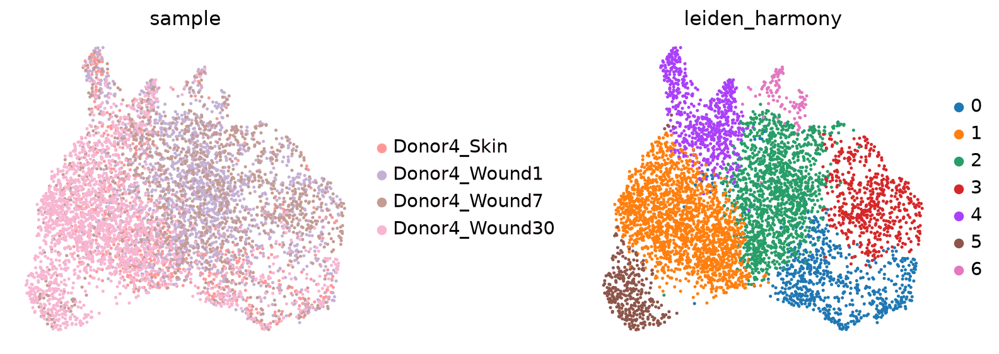

In [95]:
sc.external.pp.harmony_integrate(adata_g, key="sample")
sc.pp.neighbors(adata_g, use_rep="X_pca_harmony", key_added="harmony")
sc.tl.umap(adata_g, neighbors_key="harmony")
sc.tl.leiden(adata_g, resolution=0.5, flavor="igraph", n_iterations=2, neighbors_key="harmony", key_added="leiden_harmony")
sc.pl.umap(adata_g, color=["sample", "leiden_harmony", ], wspace=0.5)

In [96]:
pd.crosstab(adata_g.obs["leiden_harmony"], adata_g.obs["sample"], normalize="index").round(2)

sample,Donor4_Skin,Donor4_Wound1,Donor4_Wound7,Donor4_Wound30
leiden_harmony,,,,
0,0.29,0.27,0.19,0.25
1,0.19,0.09,0.10,0.62
2,0.05,0.61,0.30,0.04
3,0.06,0.39,0.52,0.03
4,0.16,0.31,0.26,0.27
5,0.01,0.00,0.19,0.81
6,0.12,0.56,0.25,0.07


Alternatives (fine, if justified): BBKNN (`sc.external.pp.bbknn`), Scanorama, scVI (heavier).
Students should not spend the morning benchmarking integration methods: one method, checked, is enough.

### D2 · Spatial domains

Expression clusters (Leiden on expression) ignore the position: neighbouring spots of the same structure can fall in different clusters,
and the maps look "salt and pepper". Spatially aware clustering uses the neighbours of each spot.

We use **CellCharter** (Varrone et al., Nature Genetics 2024, part of the scverse ecosystem): for each spot it concatenates its own
(integrated) embedding with the average embedding of its neighbours at distance 1, 2, ..., `n_layers` on the spatial graph,
then clusters this aggregated representation. It is simple, fast, works with several sections, and the code is three lines.
Alternatives (mention, do not install): BANKSY, GraphST, SpaGCN, STAGATE, BayesSpace (R). Benchmarks (Yuan et al., Nat Methods 2024)
show no method wins everywhere.

In [97]:
import cellcharter as cc

sq.gr.spatial_neighbors(adata_g, library_key="sample", coord_type="grid", n_neighs=6)
cc.gr.aggregate_neighbors(adata_g, n_layers=3, use_rep="X_pca_harmony", out_key="X_cellcharter", sample_key="sample")
adata_g.obsm["X_cellcharter"].shape

INFO     Creating graph using `None` transform and `4` libraries.                                                  


100%|██████████| 4/4 [00:00<00:00, 41.54it/s]


(5769, 120)

In [98]:
sc.pp.neighbors(adata_g, use_rep="X_cellcharter", key_added="cellcharter")
sc.tl.leiden(adata_g, resolution=0.3, flavor="igraph", n_iterations=2, neighbors_key="cellcharter", key_added="spatial_domain")
adata_g.obs["spatial_domain"].value_counts()

spatial_domain
2    1663
1    1515
0     765
5     620
3     497
4     431
6     278
Name: count, dtype: int64

CellCharter also has its own Gaussian-mixture clustering, with a scan of the number of clusters based on stability
(`cc.tl.ClusterAutoK`). It takes a few minutes per run on CPU; a fixed number of clusters is quicker:

In [99]:
gmm = cc.tl.Cluster(n_clusters=8, random_state=0)
gmm.fit(adata_g, use_rep="X_cellcharter")
adata_g.obs["spatial_domain_gmm"] = gmm.predict(adata_g, use_rep="X_cellcharter")

GPU available: False, used: False
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
GPU available: False, used: False
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
GPU available: False, used: False
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
`Trainer.fit` stopped: `max_epochs=15` reached.
GPU available: False, used: False
TPU

GPU available: False, used: False
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.


WARNING  render_shapes: Not enough colors provided for category '6', using na_color.                               


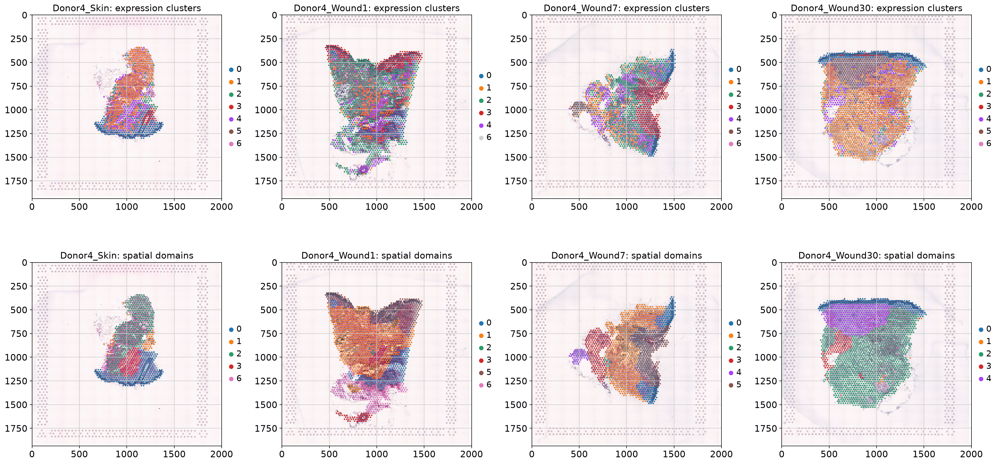

In [100]:
sdata_g.tables["table"] = adata_g
fig, axes = plt.subplots(2, len(GROUP_SAMPLES), figsize=(5.5 * len(GROUP_SAMPLES), 11))
for j, s in enumerate(GROUP_SAMPLES):
    sdata_g.pl.render_images(f"{s}_hires_image").pl.render_shapes(
        s, color="leiden_harmony", table_name="table").pl.show(
        coordinate_systems=f"{s}_downscaled_hires", ax=axes[0, j], title=f"{s}: expression clusters")
    sdata_g.pl.render_images(f"{s}_hires_image").pl.render_shapes(
        s, color="spatial_domain", table_name="table").pl.show(
        coordinate_systems=f"{s}_downscaled_hires", ax=axes[1, j], title=f"{s}: spatial domains")
plt.tight_layout()
plt.show()

Things to try (each is one parameter): `n_layers` (1 to 4: more layers, smoother and bigger domains), the Leiden resolution,
using `X_pca` instead of `X_pca_harmony` (what happens to the domains of each section?).

**Expected (option A, Donor4; 7 domains in our run, numbers may change).** Domains are contiguous on the tissue, unlike expression clusters:
- suprabasal epidermis (KRT1, KRT10, FLG), in every section;
- activated epidermis (S100A2/A7/A9, KRT6A) and a wound-edge epidermis domain (S100A7, KRT6A, S100A8): Wound1 and Wound7 only;
- inflamed wound bed (MT2A, ANXA1, NAMPT, SOD2): Wound1 only;
- quiescent collagen-rich dermis (CCDC80, COL1A2, DCN): Skin and Wound30;
- fibrotic / granulation tissue (POSTN, COL3A1, SPARC): Wound7 and, larger, Wound30 (the forming scar under the new epidermis);
- a small vascular / smooth-muscle domain (TAGLN, TPM2).

### D3 · Describe the domains

Markers of each domain, domain composition per section, neighbourhood enrichment (which domains touch each other).

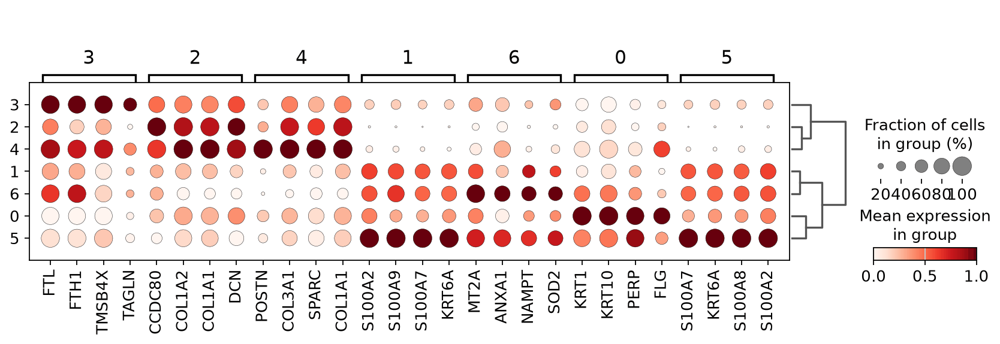

In [101]:
sc.tl.rank_genes_groups(adata_g, groupby="spatial_domain", method="wilcoxon", key_added="domain_markers")
sc.pl.rank_genes_groups_dotplot(adata_g, key="domain_markers", n_genes=4, standard_scale="var")

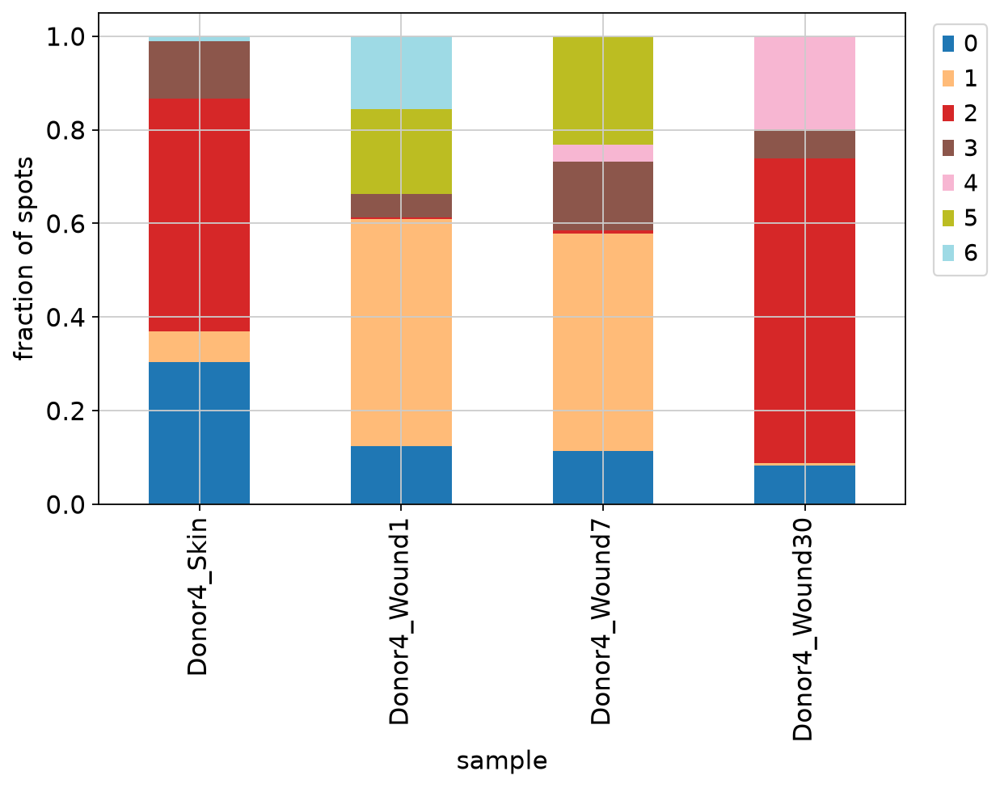

In [102]:
comp = pd.crosstab(adata_g.obs["sample"], adata_g.obs["spatial_domain"], normalize="index")
comp.plot(kind="bar", stacked=True, figsize=(8, 5), colormap="tab20")
plt.ylabel("fraction of spots")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.show()

100%|██████████| 1000/1000 [00:00<00:00, 1199.43/s]


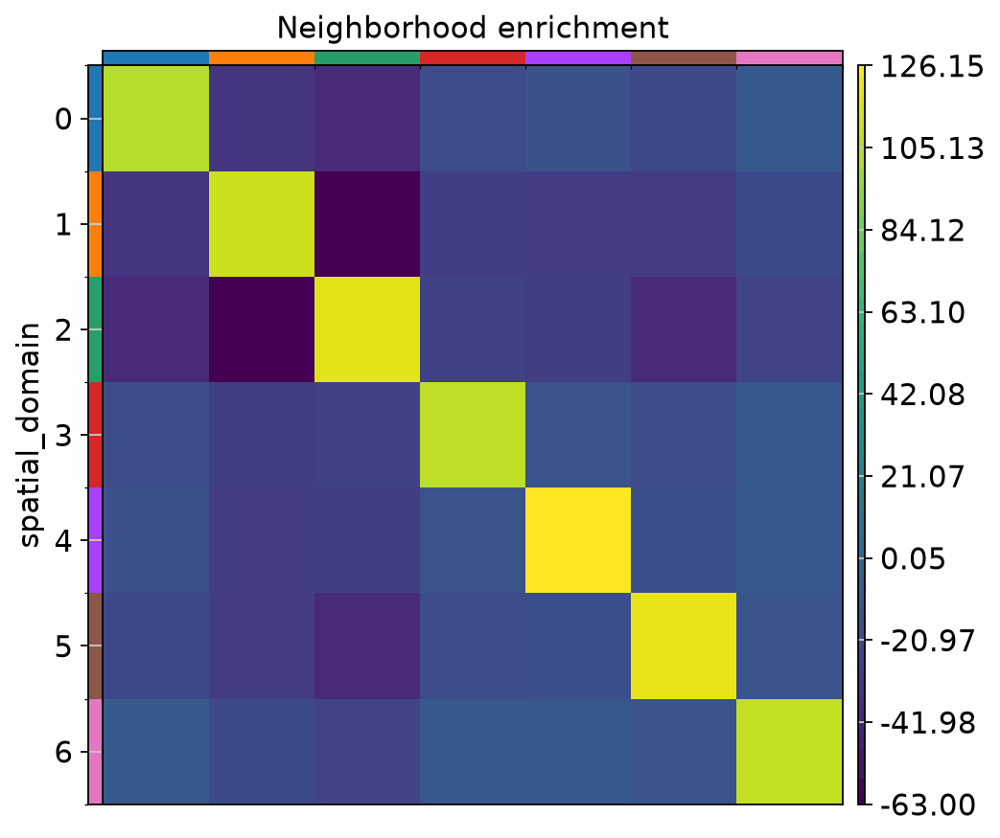

In [103]:
sq.gr.nhood_enrichment(adata_g, cluster_key="spatial_domain")
sq.pl.nhood_enrichment(adata_g, cluster_key="spatial_domain", figsize=(6, 5))

### Which domains border each other? Neighbourhood enrichment

The cell above answers this question with two steps.

**1. `sq.gr.nhood_enrichment` computes a score for every pair of spatial domains.**

- It uses the **spatial graph** built earlier (each spot is connected to its 6 neighbours on the Visium grid) and the domain label of each spot.
- For a pair of domains (A, B), it counts the edges of the graph that connect a spot of A to a spot of B: the **observed contacts**.
- It then **shuffles the domain labels** across the spots 1,000 times, keeping the graph and the size of each domain, and recounts the contacts. This gives the contacts expected if the domains were placed at random.
- The score is a **z-score**: (observed − mean of the shuffles) / standard deviation of the shuffles.
- The result is stored in `adata_g.uns["spatial_domain_nhood_enrichment"]`, with the matrices `zscore` and `count`.

**2. `sq.pl.nhood_enrichment` plots the matrix** of z-scores: one row and one column per domain.

**How to read the heatmap**

| z-score | Meaning |
|---|---|
| clearly positive | the two domains are neighbours more often than expected by chance: they **border each other** |
| close to 0 | no particular spatial relationship |
| clearly negative | the two domains are neighbours less often than expected: they are **spatially separated** |

- The **diagonal** is strongly positive. Domains are spatially coherent by construction, so a spot is mostly surrounded by spots of its own domain. This is expected and says little.
- The informative part is **off the diagonal**: which domains touch each other (for example epidermis and wound-edge tissue) and which never do (for example epidermis and adipose tissue).
- With thousands of spots the z-scores can be very large. Do not read them as p-values: look at the **sign** and compare pairs of domains with each other, not the absolute value.

**Limits**

- The graph connects each spot only to its immediate neighbours (about 100 µm), so the score measures **direct contact** between domains, not longer-range organisation.
- The null model shuffles the labels, so it preserves the size of each domain: a large domain is not "enriched" just because it is large.
- Spots of different sections are never neighbours. If the label shuffle is done on all the sections together, two domains that are present in different sections can look "separated" only because they are on different tissue pieces. Keep this in mind for options B and C, where each section is a different donor.

**Reference:** the method comes from Giotto (Dries et al., *Genome Biology* 2021) and is implemented in squidpy (Palla et al., *Nature Methods* 2022).

The neighbourhood enrichment uses the per-section graph built above, so spots of different sections are never neighbours.
Domains are spatially coherent by construction, so the diagonal is strongly positive: the interesting part is off the diagonal
(which domains border which).

### D4 · sc–st integration (afternoon)

The reference is provided (`sc_reference_mod.h5ad`): raw counts of scRNA-seq cells from PWH27 (= Donor4) and PWH28 (= Donor3),
all time points, with the `cell_type` and `newCellTypes` (fine states), subsampled to at most
300 cells per fine label. How it was built: [`cnrs-st/data/README.md`](https://github.com/sarnatas/skinwound/blob/main/cnrs-st/data/README.md).

Two approaches, from the simplest to a real mapping model:
1. **Signature scores**: markers of each cell type in the reference, then `sc.tl.score_genes` in the spots. Fast, transparent, relative (not proportions).
2. **Tangram** (Biancalani et al., Nat Methods 2021) in `clusters` mode: learns how to place the reference profiles in the spots so that the
   predicted spot expression matches the measured one. Gives a cell-type density per spot. CPU, seconds per section.

Cell2location (Kleshchevnikov et al., Nat Biotechnol 2022) is the reference method used in many papers, but on CPU it takes hours
(≈ 20 h for 4 sections on a laptop in our tests): only with a GPU, or as a precomputed result to compare.

In [126]:
ref = sc.read_h5ad(f"{DATA}/sc_reference_mod.h5ad")
ref.layers["counts"] = ref.X.copy()
sc.pp.normalize_total(ref, target_sum=1e4)
sc.pp.log1p(ref)
ref.obs["cell_type"].value_counts()

cell_type
Keratinocyte              2400
Myeloid                   1317
Fibroblast                1200
Lymphoid                   900
Endothelial                547
Hair_follicle              300
Mast                       300
Melanocyte                 300
Pericyte_Smooth_muscle     300
Schwann                    146
Name: count, dtype: int64

In [127]:
sc.tl.rank_genes_groups(ref, groupby="cell_type", method="wilcoxon", key_added="ref_markers")
ref_markers = sc.get.rank_genes_groups_df(ref, group=None, key="ref_markers")
ref_markers = ref_markers[(ref_markers["logfoldchanges"] > 1) & (ref_markers["pvals_adj"] < 0.01)]
signatures = {}
for ct, df in ref_markers.groupby("group", observed=True):
    signatures[ct] = df.sort_values("scores", ascending=False)["names"].head(25).tolist()
{k: v[:6] for k, v in signatures.items()}

{'Endothelial': ['GNG11', 'TM4SF1', 'PECAM1', 'PCAT19', 'ECSCR', 'RAMP2'],
 'Fibroblast': ['DCN', 'COL6A2', 'COL6A1', 'COL1A2', 'COL1A1', 'COL6A3'],
 'Hair_follicle': ['RBP1', 'MIR205HG', 'SOX9', 'CAPNS2', 'CXADR', 'PALMD'],
 'Keratinocyte': ['SFN', 'PERP', 'LY6D', 'DSG1', 'S100A14', 'AQP3'],
 'Lymphoid': ['RPS27', 'PTPRC', 'SRGN', 'STK4', 'B2M', 'CXCR4'],
 'Mast': ['HPGD', 'TPSB2', 'TPSAB1', 'CPA3', 'CTSG', 'HPGDS'],
 'Melanocyte': ['MLANA', 'DCT', 'TYRP1', 'CAPN3', 'PMEL', 'CD59'],
 'Myeloid': ['HLA-DRA',
  'CD74',
  'HLA-DPA1',
  'HLA-DPB1',
  'HLA-DRB1',
  'HLA-DQB1'],
 'Pericyte_Smooth_muscle': ['TAGLN', 'TPM2', 'MCAM', 'MYL9', 'CALD1', 'ACTA2'],
 'Schwann': ['S100A6', 'CNN3', 'ITGB1', 'TNFRSF12A', 'S100A13', 'COL4A2']}

### Marker genes of each cell type = our "signatures"

The cell above builds, for each of the 10 cell types of the reference, a short list of marker genes (a **signature**). We will use these lists in the next steps: first to score the spots, then to choose the genes given to Tangram.

**What the code does**

1. `rank_genes_groups` tests every gene for each cell type, comparing the cells of that type with **all the other cells** ("one versus rest"). The test is the **Wilcoxon rank-sum test** (also called Mann–Whitney U): all cells are ranked by their expression of the gene, and we ask whether the cells of the group tend to have higher ranks than the others. It uses the log-normalised values and does not assume a normal distribution of the expression.
2. For each gene and cell type we get:
   - `scores`: the test statistic as a z-score. The larger it is, the more consistently the gene is higher in the group.
   - `logfoldchanges`: log2 of the ratio of the mean expression in the group versus the rest, computed on the non-logged scale. A value of 1 means twice as high.
   - `pvals_adj`: the p-value corrected for the many genes tested (Benjamini–Hochberg).
3. We keep the genes with `logfoldchanges > 1` and `pvals_adj < 0.01`, sort them by `scores`, and keep the **top 25 per cell type**.
4. The last line prints the first 6 genes of each signature as a quick sanity check: do they look like known markers of the cell type?

**How to read the choices**

- **Ranking by `scores`, not by p-value.** With thousands of cells almost every gene with a difference has a tiny p-value, so p-values do not discriminate. They are tiny also because the test treats cells as independent replicates, which they are not (cells of the same patient and sample are correlated). This is acceptable to **select markers**, but it is not valid for statistical inference between conditions: for that, we aggregate per sample (pseudobulk, see C7).
- **Fold change and p-value play different roles.** The p-value says that there is a difference, the fold change says that the difference is large enough to be useful as a marker.
- **Group sizes differ** (from 146 Schwann cells to 2,400 keratinocytes, because we subsampled by fine label). The z-score grows with the number of cells, so compare genes **within** a cell type, not scores across cell types.
- **"One versus rest" favours very specific genes.** A gene shared by two related types (for example keratinocytes and hair follicle cells) is penalised in both, because the "rest" contains the other type. So the signatures contain what makes a type different from everything else, not necessarily what defines it.
- **25 genes is a choice**: enough to give a stable score per spot, few enough to stay specific. A type can have fewer than 25 genes if few pass the filters. It is worth checking: `{k: len(v) for k, v in signatures.items()}`.

**Next:** the signatures are used to score each spot (`sc.tl.score_genes`) and to select the genes used by Tangram.

**References:** Wolf et al., *Genome Biology* 2018 (Scanpy); Soneson & Robinson, *Nature Methods* 2018 (comparison of differential expression methods for single-cell data); Squair et al., *Nature Communications* 2021 (false discoveries from treating cells as replicates).

In [129]:
for ct, genes in signatures.items():
    sc.tl.score_genes(adata_g, [g for g in genes if g in adata_g.var_names], score_name=f"score_{ct}")

Tangram, one section at a time (each section is mapped on its own; the reference is the same).

### Tangram: placing a single-cell reference in space

**The problem.** Visium measures all genes, but each spot mixes several cells (up to ~10–20 in skin). scRNA-seq tells us which cell types exist and what they express, but not where they are. Tangram (Biancalani et al., *Nature Methods* 2021) puts the two together: it learns **where the cell types of the reference are located in the tissue**, so that the expression it predicts in each spot matches the one we measured.

**The idea, in four steps**

1. We give Tangram a set of **training genes** (here the union of the signatures built above: genes that distinguish the cell types).
2. Tangram looks for a **mapping matrix** $M$ with one row per reference unit (a cell, or here a cell type) and one column per spot. $M_{ij}$ says how much of unit $i$ is placed in spot $j$.
3. With $S$ = expression of the reference (units × genes) and $G$ = measured expression of the spots (spots × genes), the **predicted expression** of the spots is
   $$G_{pred} = M^{T} S$$
4. $M$ is **optimised by gradient descent** (PyTorch) to make $G_{pred}$ as similar as possible to $G$ on the training genes. The similarity is based on the cosine between predicted and measured expression of each gene across the spots. After a number of epochs the loss stops decreasing and $M$ is our map.

**Three modes**

- `cells` (default): every cell of the reference is mapped individually. It gives a position for each cell but needs more memory and time.
- `clusters` (**used here**): cells are first averaged into one profile per group (`cluster_label="cell_type"`), and these profiles are mapped. It is much faster, which is why we can run it on CPU, but we lose the information on individual cells.
- `constrained`: like `cells`, but with a known or estimated number of cells per spot.

**What we do in the next cell**

- `tg.pp_adatas(ref, sp, genes=...)` keeps the training genes present in both objects and prepares the data.
- `tg.map_cells_to_space(..., mode="clusters", cluster_label="cell_type", num_epochs=500)` learns $M$, one section at a time. `device="cpu"` is enough in this mode.
- `tg.project_cell_annotations(...)` turns $M$ into one column per cell type, stored in `obsm["tangram_ct_pred"]` and then copied into `adata_g.obs` as `tangram_<cell type>`.

**What you get, and what you do not**

- In `clusters` mode each cell type is a **distribution over the spots of a section** (it sums to 1 per section). It tells where a type goes, not how many cells are in a spot, and it cannot say that a

In [130]:
import tangram as tg

tangram_genes = sorted(set(sum([v[:50] for v in signatures.values()], [])))
tangram_results = []
for s in GROUP_SAMPLES:
    sp = adata_g[adata_g.obs["sample"] == s].copy()
    tg.pp_adatas(ref, sp, genes=tangram_genes)
    ad_map = tg.map_cells_to_space(ref, sp, mode="clusters", cluster_label="cell_type",
                                   device="cpu", num_epochs=500, verbose=False)
    tg.project_cell_annotations(ad_map, sp, annotation="cell_type")
    tangram_results.append(sp.obsm["tangram_ct_pred"])

tangram_pred = pd.concat(tangram_results).loc[adata_g.obs_names]
for ct in tangram_pred.columns:
    adata_g.obs[f"tangram_{ct}"] = tangram_pred[ct].values
tangram_pred.describe().T[["mean", "max"]]

INFO:root:233 training genes are saved in `uns``training_genes` of both single cell and spatial Anndatas.
INFO:root:17748 overlapped genes are saved in `uns``overlap_genes` of both single cell and spatial Anndatas.
INFO:root:uniform based density prior is calculated and saved in `obs``uniform_density` of the spatial Anndata.
INFO:root:rna count based density prior is calculated and saved in `obs``rna_count_based_density` of the spatial Anndata.
INFO:root:Allocate tensors for mapping.
INFO:root:Begin training with 233 genes and rna_count_based density_prior in clusters mode...
INFO:root:Saving results..
INFO:root:spatial prediction dataframe is saved in `obsm` `tangram_ct_pred` of the spatial AnnData.
INFO:root:233 training genes are saved in `uns``training_genes` of both single cell and spatial Anndatas.
INFO:root:19076 overlapped genes are saved in `uns``overlap_genes` of both single cell and spatial Anndatas.
INFO:root:uniform based density prior is calculated and saved in `obs``unif

,mean,max
Keratinocyte,0.000693,0.007010
Myeloid,0.000693,0.013407
Fibroblast,0.000693,0.006305
Lymphoid,0.000693,0.021100
Endothelial,0.000693,0.020611
Hair_follicle,0.000693,0.030586
Mast,0.000693,0.022519
Melanocyte,0.000693,0.018860
Pericyte_Smooth_muscle,0.000693,0.019027
Schwann,0.000693,0.051991


### Reading the Tangram output

The table shows, for each cell type, the **mean** and the **maximum** of the Tangram value over all the spots of the sections we mapped.

**Why the mean is the same for all cell types**

In `clusters` mode, Tangram takes the average profile of each cell type and **distributes it over the spots of a section**. For each section the values of one cell type sum to 1, so they are a distribution over the spots, not a number of cells. With 4 sections the total is 4 for every cell type, and the mean is always 4 divided by the number of spots (here 4 / 0.000693 ≈ 5,770 spots, which is the number of rows of `adata_g`). So **the mean carries no information**: it is the normalisation, not a result. You can check it with `tangram_pred.groupby(adata_g.obs["sample"]).sum()`, which should give 1 everywhere.

**What the maximum tells us**

The maximum is the largest share of a cell type given to a single spot, so it measures **how concentrated** the cell type is. A perfectly uniform distribution would give every spot about the value of the mean. The ratio max / mean is a quick indicator:

- **Large ratio** (Schwann, hair follicle, mast cells, lymphoid, endothelial cells; roughly 30 to 75): the type is placed in a few spots, as expected for small structures (nerves, follicles, vessels, immune infiltrates).
- **Small ratio** (fibroblasts, keratinocytes; roughly 10): the type is spread over many spots, as expected for the large compartments of the dermis and the epidermis, where the contrast between spots is low.

**What this table cannot say**

- The values are **not proportions and not cell counts**. A high maximum means "concentrated in a few spots", not "abundant". Compare the spots of one cell type with each other, not different cell types.
- Every cell type receives a total of 1 **in every section**, even a type that is absent from that section: it is then placed on the most similar spots. The output therefore says **where** each type goes inside a section, not **how much** of it there is. We cannot use it alone to say that a type increases between time points.

To check that the mapping makes sense, we compare it with the signature scores and with marker genes measured directly in the spots (next cells).

**How to read the Tangram output in `clusters` mode.** Each cell type is one averaged profile that Tangram distributes over the spots
of the section, so each column sums to 1 **over the spots of a section**: it says *where* a cell type goes, not *how many cells* are in a spot.
Do not normalise per spot to call it a proportion (rare types would be inflated). For per-spot cell numbers: Tangram `cells` mode on
a reference with realistic composition (slower), or cell2location.

Do the two approaches agree, and do they agree with single marker genes measured directly in the spots
(an independent check, since these genes are in the spot data, not in the reference)?

In [131]:
check = [("Keratinocyte", "KRT14"), ("Fibroblast", "COL1A1"), ("Myeloid", "LYZ"), ("Endothelial", "VWF"),
         ("Pericyte_Smooth_muscle", "TAGLN"), ("Mast", "TPSB2")]
rows = []
for ct, gene in check:
    if ct in tangram_pred.columns and gene in adata_g.var_names:
        g = adata_g[:, gene].X.toarray().ravel()
        rows.append({"cell type": ct, "gene": gene,
                     "tangram vs score": np.corrcoef(adata_g.obs[f"tangram_{ct}"], adata_g.obs[f"score_{ct}"])[0, 1],
                     "tangram vs gene": np.corrcoef(adata_g.obs[f"tangram_{ct}"], g)[0, 1],
                     "score vs gene": np.corrcoef(adata_g.obs[f"score_{ct}"], g)[0, 1]})
pd.DataFrame(rows).round(2)

,cell type,gene,tangram vs score,tangram vs gene,score vs gene
0,Keratinocyte,KRT14,0.75,0.39,0.61
1,Fibroblast,COL1A1,0.48,0.31,0.80
2,Myeloid,LYZ,0.63,0.38,0.54
3,Endothelial,VWF,0.67,0.27,0.34
4,Pericyte_Smooth_muscle,TAGLN,0.76,0.57,0.60
5,Mast,TPSB2,0.52,0.53,0.45


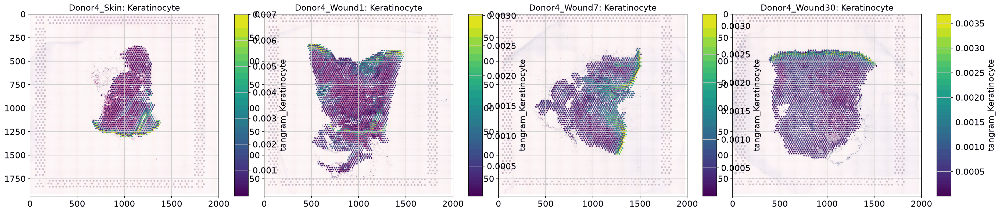

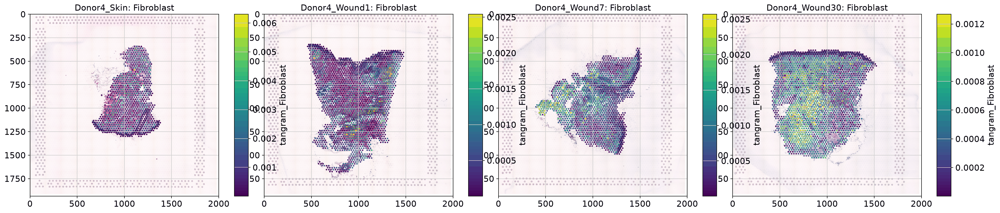

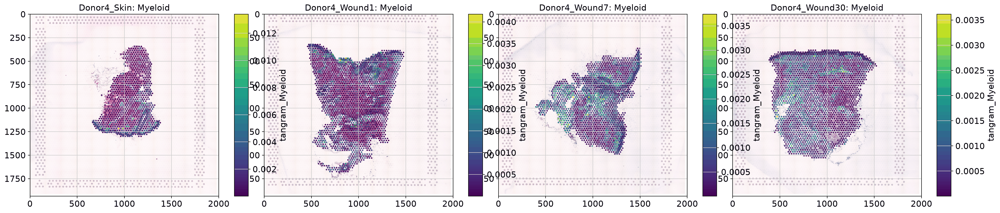

In [132]:
sdata_g.tables["table"] = adata_g
for ct in ["Keratinocyte", "Fibroblast", "Myeloid"]:
    fig, axes = plt.subplots(1, len(GROUP_SAMPLES), figsize=(5.5 * len(GROUP_SAMPLES), 5.5))
    for j, s in enumerate(GROUP_SAMPLES):
        sdata_g.pl.render_images(f"{s}_hires_image").pl.render_shapes(
            s, color=f"tangram_{ct}", table_name="table").pl.show(
            coordinate_systems=f"{s}_downscaled_hires", ax=axes[j], title=f"{s}: {ct}")
    plt.tight_layout()
    plt.show()

### Reading the Tangram maps

Each figure shows one cell type over the four sections. The colour of a spot is the Tangram value of that cell type: **how much of that cell type was placed in the spot**, compared with the other spots of the same section.

**How to read them**

- **Each panel has its own colour scale.** In `clusters` mode the values of a cell type sum to 1 within each section, so the map says **where** the type is inside the section. It does not say how much of the type there is, and we cannot compare colour intensities between sections.
- **Compare each map with the H&E** below it: does the pattern follow a structure that you can recognise (epidermis, dermis, wound bed)?
- **Compare the three cell types** with each other: they should occupy different parts of the tissue.

**Expected (option A).**

- **Keratinocytes** map to the **epidermis**, and in the wounds in particular to the wound edge.
- **Fibroblasts** are spread over the **dermis**, with little contrast between spots: fibroblasts are present everywhere in the dermis, so the probability is diluted over many spots.
- **Myeloid cells** concentrate in the **wound bed** at Wound1 and Wound7, where the inflammation is.
- The three patterns should be largely **complementary**: a spot that is strongly keratinocyte is rarely strongly fibroblast.

**What these maps cannot say**

- They show localisation, not abundance: a bright patch means "this is where the type goes", not "many cells". For the cell numbers per spot you would need Tangram in `cells` mode or cell2location.
- Rare types (Schwann cells, melanocytes, hair follicle) are less reliable at the 55 µm resolution of Visium: Tangram has to place them somewhere, even where they are not.
- A good map is a hypothesis, not a proof. In the next cells we check it against the signature scores and against marker genes measured directly in the spots.

**Expected (option A).** Tangram and signature scores agree well for the major types (r ≈ 0.65–0.77 for keratinocytes, myeloid,
endothelial, pericytes/smooth muscle), less for fibroblasts (0.40: fibroblasts are everywhere in the dermis, with little contrast).
Against single genes the correlations are moderate (0.27–0.55): one gene is noisy in one spot. Keratinocytes map to the epidermis and the
wound edge; myeloid cells to the wound bed at Wound1/Wound7. Rare types (Schwann cells, melanocytes, hair follicle) are unreliable at 55 µm:
Tangram still has to put them somewhere.
In option B (other donors), the reference comes partly from other individuals: a good discussion on how far a reference can be "borrowed".

### D5 · Linking domains and cell types, over time

In which domains does each cell type go (Tangram density averaged per domain, scaled per cell type)?
And the domain composition per condition from D3.

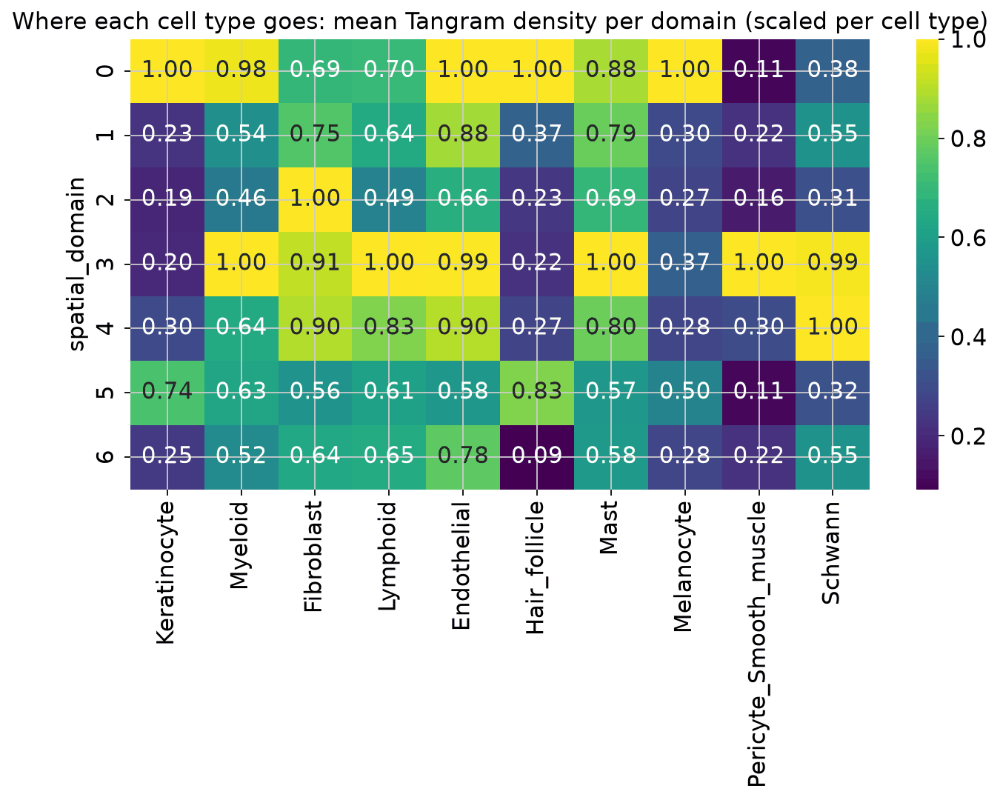

In [133]:
ct_cols = [f"tangram_{ct}" for ct in tangram_pred.columns]
domain_ct = adata_g.obs.groupby("spatial_domain", observed=True)[ct_cols].mean()
domain_ct.columns = [c.replace("tangram_", "") for c in domain_ct.columns]
domain_ct = domain_ct / domain_ct.max(axis=0)          # each cell type scaled to its best domain
plt.figure(figsize=(10, 5))
sns.heatmap(domain_ct, cmap="viridis", annot=True, fmt=".2f")
plt.title("Where each cell type goes: mean Tangram density per domain (scaled per cell type)")
plt.show()

### Reading the domain × cell type heatmap

Each cell of the heatmap is the **mean Tangram value of one cell type in the spots of one spatial domain**. Each column is then divided by its maximum, so for every cell type the domain where it goes the most is **1.00** and the others are shown as a fraction of it.

**How to read it**

- **Read by column**: "in which domain(s) does this cell type go?" A column with a single bright cell means that the type is concentrated in one domain; a column with several bright cells means that it is shared.
- **Read by row**: "which cell types make up this domain?" A row with one bright cell is dominated by one type; a row with several bright cells is a mix.
- A **row with no bright cell** is a domain that no cell type of the reference explains best. This usually means a structure that is missing from the reference (for example glands), or a mixed domain.

**Expected (option A; names of the domains from the marker genes in D3).**

- **Keratinocytes** should be highest in the **epidermal domains** (suprabasal, activated and wound-edge epidermis).
- **Fibroblasts** should go to the **dermal domains** (quiescent collagen-rich dermis, and fibrotic or granulation tissue in the wounds), with less contrast, as seen on the maps.
- **Myeloid cells** should go to the **inflamed wound bed**, which is present in the early wound.
- **Endothelial cells and pericytes / smooth muscle** should go to the small **vascular domain**.
- The map is a way to **check the domains**: if a domain named "epidermis" does not light up for keratinocytes, either the name or the mapping is wrong.

**What it does not tell us**

- Each column is scaled **separately**, so we cannot compare colours between cell types: 1.00 for a rare type and 1.00 for a common one mean the same thing, "its best domain".
- The values are not cell counts or proportions. A domain with a high value for a type is where Tangram places that type, not necessarily where most of its cells are.
- Tangram values sum to 1 **within each section**, so spots of smaller sections have higher values by construction. A domain made mostly of spots from a small section (here Skin) can look enriched for this reason. Keep it in mind before concluding.
- With one donor (option A) there are no replicates: we can describe what we see, not test it.

In [134]:
sdata_g.tables["table"] = adata_g
sdata_g.write(f"{OUT}/group_project.zarr", overwrite=True)

### D6 · What we expect in the presentations (15:30, 10 min per group)

- The question and the sections chosen, and why.
- QC and filtering decisions, in one slide.
- Integration: before/after, and how they checked it did not erase biology.
- Spatial domains on the tissue, with their markers and a name.
- Cell types in space (Tangram and/or scores), with one independent check.
- One biological message (for example: "the wound-edge domain appears at Wound1, peaks at Wound7 and is enriched in myeloid cells"), and the limits:
  spot resolution, number of donors, borrowed reference, depth differences between sections.

### Troubleshooting seen during testing

| Error | Cause | Fix |
|---|---|---|
| `Value passed for key 'X_pca_harmony' is of incorrect shape` | harmonypy ≥ 0.2 | `pip install harmonypy==0.0.10` (or call `harmonypy.run_harmony` and transpose `Z_corr` if needed) |
| `'csr_array' object has no attribute 'getnnz'` in `sc.pp.neighbors` | pynndescent 0.7 / scikit-learn 1.9 with scanpy 1.11 | `pip install "pynndescent<0.6" "scikit-learn<1.8"` |
| Barcodes `...-1-1`, metadata does not match | barcodes made unique by `concatenate` | prefix `obs_names` with the sample name **before** concatenating (A2) |
| Empty or wrong plot with `render_shapes(color=...)` | table does not annotate that shape element, or `table_name` missing | check `sdata["table"].uns["spatialdata_attrs"]` and the `region` column |
| `ValidationError: Table contains invalid names` when writing or re-attaching the table | column names with spaces or `&` (e.g. cell-type names used as `obs` columns) | clean the labels first (D4), or `spatialdata.utils.sanitize_table(adata)` |
| `KeyError` on a gene in plots | gene removed by the filters, or duplicated symbol renamed (`-1`) | check `gene in adata.var_names` |